# Image Captioning Project

Welcome to this Image Captioning notebook! In this project, we will build an AI model that can automatically generate descriptions for images.


# 1. Problem Understanding

Image captioning means generating a simple English sentence to describe what is happening in an image.

The input is an image, and the output is a text description of that image.

We will use two main parts to do this:
1. A CNN encoder to look at the image and extract its main features.
2. An LSTM decoder to take those features and write the description word by word.

## Notebook Workflow

The following workflow describes the complete image captioning process, from dataset preparation to model evaluation and final analysis.

```text
                 IMAGE CAPTIONING PROJECT
                           |
                           v
              1. DATASET LOADING
             (Obtain Flickr8k dataset)
                           |
                           v
              2. DATASET EXPLORATION
       (Understand images, captions and data structure)
                           |
                           v
             3. CAPTION PREPROCESSING
       (Lowercase, remove punctuation, add start/end
                    tokens and clean text)
                           |
                           v
              4. IMAGE-BASED DATA SPLIT
       (6000 training, 1000 validation, 1091 test images;
              prevent image leakage between sets)
                           |
                           v
              5. CAPTION ANALYSIS
       (Study caption lengths, word frequencies and
                 vocabulary distribution)
                           |
                           v
              6. VOCABULARY CREATION
       (Build vocabulary using training captions only;
          apply minimum frequency threshold of 5)
                           |
                           v
             7. TEXT SEQUENCE PREPARATION
       (Convert words into numerical tokens and apply
                  padding to equalize lengths)
                           |
                           v
              8. IMAGE FEATURE EXTRACTION
       (Use frozen ImageNet-pretrained CNNs and cache
                    features for reuse)
                           |
                +----------+----------+
                |                     |
                v                     v
        MODEL 1: RESNET50      MODEL 2: EFFICIENTNET-B0
                |                     |
                v                     v
         Extract image         Extract image
         features (2048)       features (1280)
                |                     |
                v                     v
         Image projection      Image projection
         + Caption Embedding   + Caption Embedding
                |                     |
                v                     v
           LSTM NETWORK          LSTM NETWORK
                |                     |
                v                     v
        Feature Combination   Feature Combination
                |                     |
                v                     v
        Vocabulary Prediction Vocabulary Prediction
                |                     |
                v                     v
          MODEL 1 TRAINING       MODEL 2 TRAINING
        (Learn image-caption   (Learn image-caption
         relationships)         relationships)
                |                     |
                v                     v
         Save Best Model       Save Best Model
        (Use validation loss   (Use validation loss
         and early stopping)    and early stopping)
                |                     |
                +----------+----------+
                           |
                           v
                9. CAPTION GENERATION
            (Use the same 1091 test images)
                           |
              +------------+------------+
              |            |            |
              v            v            v
           GREEDY       BEAM SEARCH   BEAM SEARCH
           SEARCH        (k = 3)       (k = 5)
              |            |            |
              +------------+------------+
                           |
                           v
                10. BLEU EVALUATION
       (Calculate BLEU-1, BLEU-2, BLEU-3 and BLEU-4
          against all five reference captions)
                           |
                           v
                11. MODEL COMPARISON
       (Compare both CNN backbones and all decoding
                  strategies on the same test set)
                           |
                           v
                12. TRAINING ANALYSIS
       (Compare training/validation loss curves,
          training time and hardware information)
                           |
                           v
                13. CAPTION DIVERSITY
       (Count distinct words generated by each model
                   and decoding method)
                           |
                           v
                14. QUALITATIVE EVALUATION
       (Inspect six image-caption examples: three good
                   and three poor predictions)
                           |
                           v
                15. ERROR ANALYSIS
       (Identify object, colour, action, counting,
              repetition and unknown-word errors)
                           |
                           v
                16. FINAL CONCLUSION
       (Summarize experimental results, compare models
              and discuss their limitations)
```

### Why This Workflow?

Each stage prepares the output required by the next stage. The dataset is split before vocabulary creation to prevent data leakage. Two different frozen CNN backbones are used to compare image feature extraction. Both models use the same captioning architecture and test images, allowing a fair comparison. Finally, numerical metrics and visual inspection are combined to evaluate caption quality.

### 1.1 Preparing Environment and Downloading Kaggle Dataset

To begin our project, we must configure Kaggle credentials in Colab and download our dataset. The cell below installs the required Kaggle tool, securely writes the access credentials, and downloads the Flickr8k dataset to our workspace.

### Why do we need to do this?

* **Kaggle API:** We cannot download huge datasets manually in Google Colab. Using the official Kaggle library makes it quick, safe, and fully automated.
* **Folder Setup:** We create a dedicated `/content/data` folder to keep our raw zip and extracted files separated from other code outputs.

# 2. Dataset Understanding

We are using the Flickr8k dataset for this project.

This dataset has 8,091 images. Each image has 5 different descriptions written by humans. This makes a total of 40,455 sentences.

We will split the images into three groups:
- Training: 6,000 images to teach the model.
- Validation: 1,000 images to check the model's performance during training.
- Testing: 1,091 images to do the final test of the model.

We group by image, not by single sentences. This means all 5 descriptions of a single image will stay together in the same group so the model does not cheat.

# 3. Downloading the Dataset

We will download the Flickr8k dataset from Kaggle. We will use the Kaggle API to download the files and extract them into our workspace.

In [1]:

!pip -q install kaggle

import os
import json

# Enter your Kaggle credentials here
kaggle_username = "ZainULLAbideen987"
kaggle_key = "KGAT_5617dca022e6dd0da82c2ffa56467a3e"

# Create Kaggle configuration
os.makedirs("/root/.kaggle", exist_ok=True)

credentials = {
    "username": kaggle_username,
    "key": kaggle_key
}

with open("/root/.kaggle/kaggle.json", "w") as file:
    json.dump(credentials, file)

os.chmod("/root/.kaggle/kaggle.json", 0o600)

# Create dataset folder
os.makedirs("/content/data", exist_ok=True)

# Download Flickr8k
!kaggle datasets download -d adityajn105/flickr8k -p /content/data --unzip

print("Dataset download completed!")


Dataset URL: https://www.kaggle.com/datasets/adityajn105/flickr8k
License(s): CC0-1.0
100% 1.04G/1.04G [00:07<00:00, 147MB/s]

Dataset download completed!


# 4. Dataset Inspection

Now we will check the downloaded files. We want to see the folder structure, count the total number of images, and read a few lines of the text files to see how they are formatted.

In [2]:

from pathlib import Path

# Main dataset directory
data_root = Path("/content/data")

# Display folder structure
print("DATASET FOLDER CONTENTS\n")

for item in sorted(data_root.iterdir()):
    if item.is_dir():
        print(f"Folder: {item.name}")
    else:
        print(f"File: {item.name}")

# Find all image files
image_extensions = {".jpg", ".jpeg", ".png"}

image_files = [
    path for path in data_root.rglob("*")
    if path.is_file() and path.suffix.lower() in image_extensions
]

# Find text and caption files
text_files = [
    path for path in data_root.rglob("*")
    if path.is_file() and path.suffix.lower() in {".txt", ".csv"}
]

print("\nTOTAL IMAGES:", len(image_files))

print("\nTEXT / CAPTION FILES:")
for path in text_files:
    print(path)

# Display a small sample of the first text file
if text_files:
    caption_path = text_files[0]

    print("\nSAMPLE CONTENT FROM:", caption_path.name)

    with open(caption_path, "r", encoding="utf-8") as file:
        for _ in range(8):
            line = file.readline()
            if not line:
                break
            print(line.strip())
else:
    print("\nNo text or caption file found.")


DATASET FOLDER CONTENTS

Folder: Images
File: captions.txt

TOTAL IMAGES: 8091

TEXT / CAPTION FILES:
/content/data/captions.txt

SAMPLE CONTENT FROM: captions.txt
image,caption
1000268201_693b08cb0e.jpg,A child in a pink dress is climbing up a set of stairs in an entry way .
1000268201_693b08cb0e.jpg,A girl going into a wooden building .
1000268201_693b08cb0e.jpg,A little girl climbing into a wooden playhouse .
1000268201_693b08cb0e.jpg,A little girl climbing the stairs to her playhouse .
1000268201_693b08cb0e.jpg,A little girl in a pink dress going into a wooden cabin .
1001773457_577c3a7d70.jpg,A black dog and a spotted dog are fighting
1001773457_577c3a7d70.jpg,A black dog and a tri-colored dog playing with each other on the road .


# 5. Caption File Verification

The dataset has two files with descriptions. We will compare them to see if they are the same.

We will also count the number of images and sentences to make sure every image has exactly 5 descriptions.

In [5]:
from pathlib import Path
import pandas as pd

# Define caption file path
file1 = Path("/content/data/captions.txt")

print("LOADING CAPTIONS FILE")
# Load caption file
df1 = pd.read_csv(file1, sep=",")

print("ORIGINAL SHAPE:", df1.shape)

# Clean up columns to match standard naming
df1 = df1.rename(columns={"image": "image_name", "caption": "caption_text"})

# We will use df1 as our primary dataframe
captions_df = df1.copy()

# Remove accidental whitespace from column names if any
captions_df.columns = captions_df.columns.str.strip()

# Display dataset information
print("\nCAPTION DATA INFORMATION")
print("Total caption records:", len(captions_df))
print("Unique images:", captions_df["image_name"].nunique())

# Count captions per image
captions_per_image = captions_df.groupby("image_name").size()

print("\nCAPTIONS PER IMAGE")
print(captions_per_image.value_counts().sort_index())

# Check whether every image has exactly five captions
print("\nImages with exactly 5 captions:",
      (captions_per_image == 5).sum())

print("Images without exactly 5 captions:",
      (captions_per_image != 5).sum())

# Display first five records
print("\nFIRST FIVE CAPTION RECORDS")
display(captions_df.head())

LOADING CAPTIONS FILE
ORIGINAL SHAPE: (40455, 2)

CAPTION DATA INFORMATION
Total caption records: 40455
Unique images: 8091

CAPTIONS PER IMAGE
5    8091
Name: count, dtype: int64

Images with exactly 5 captions: 8091
Images without exactly 5 captions: 0

FIRST FIVE CAPTION RECORDS


,image_name,caption_text
0,1000268201_693b08cb0e.jpg,A child in a pink dress is climbing up a set o...
1,1000268201_693b08cb0e.jpg,A girl going into a wooden building .
2,1000268201_693b08cb0e.jpg,A little girl climbing into a wooden playhouse .
3,1000268201_693b08cb0e.jpg,A little girl climbing the stairs to her playh...
4,1000268201_693b08cb0e.jpg,A little girl in a pink dress going into a woo...


# 6. Final Caption Data Verification

We will compare the image names and descriptions from both files to make sure they match.

We will use the file with three columns because it includes description numbers. We will also check for empty rows, double entries, and make sure the image files actually exist in the folder.

### What are we verifying here?

* **No Empty Lines:** Checking if there are any blank text rows in our captions dataframe that could cause model errors.
* **Perfect Balance:** Ensuring every single unique image contains exactly **5** human descriptions.
* **Correct Paths:** Verifying that the files are present locally and can be read with a standard pandas CSV reader.

### 7. Same Image Caption Comparison

To make sure both files have the same descriptions for the same image, we will pick one image and print its sentences from both files side by side to compare them.

In [7]:
# Select a sample image
sample_image = captions_df["image_name"].iloc[0]

# Filter captions for the selected image from our captions dataframe
sample_captions = captions_df[captions_df["image_name"] == sample_image]["caption_text"].tolist()

print(f"CAPTIONS FOR IMAGE: {sample_image}\n")

for i, caption in enumerate(sample_captions, 1):
    print(f"{i}. {caption}")

CAPTIONS FOR IMAGE: 1000268201_693b08cb0e.jpg

1. A child in a pink dress is climbing up a set of stairs in an entry way .
2. A girl going into a wooden building .
3. A little girl climbing into a wooden playhouse .
4. A little girl climbing the stairs to her playhouse .
5. A little girl in a pink dress going into a wooden cabin .


### 7.1 Visualizing the Sample Image

Before jumping into math and deep learning, it is always a good practice to physically look at a sample image and read its descriptions.

This lets us verify:
* If the image files are opening correctly.
* How well the human descriptions match the actual visual objects in the picture.

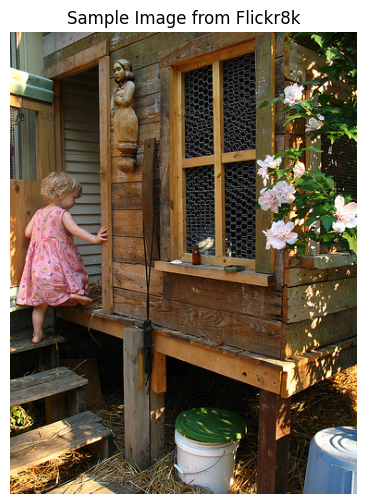

IMAGE: 1000268201_693b08cb0e.jpg

HUMAN-WRITTEN CAPTIONS:

1. A child in a pink dress is climbing up a set of stairs in an entry way .
2. A girl going into a wooden building .
3. A little girl climbing into a wooden playhouse .
4. A little girl climbing the stairs to her playhouse .
5. A little girl in a pink dress going into a wooden cabin .


In [8]:
import matplotlib.pyplot as plt
from PIL import Image
from pathlib import Path

# Define the directory where images are stored
images_dir = Path("/content/data/Images")

# Select one image
sample_image = captions_df["image_name"].iloc[0]

# Load the image
image_path = images_dir / sample_image
image = Image.open(image_path)

# Get all five captions
sample_captions = captions_df[
    captions_df["image_name"] == sample_image
]["caption_text"].tolist()

# Display image
plt.figure(figsize=(8, 6))
plt.imshow(image)
plt.axis("off")
plt.title("Sample Image from Flickr8k")
plt.show()

# Display its captions
print("IMAGE:", sample_image)
print("\nHUMAN-WRITTEN CAPTIONS:\n")

for i, caption in enumerate(sample_captions, 1):
    print(f"{i}. {caption}")

# 8. Caption Preprocessing

Before we train the model, we need to clean the text descriptions:

1. Change all letters to lowercase.
2. Remove all punctuation like dots, commas, and question marks.
3. Put a '<start>' token at the beginning of each sentence.
4. Put an '<end>' token at the end of each sentence.

These tokens help the model know when to start and stop writing a sentence.

In [9]:

import re

# Create a copy of the original caption dataset
processed_captions = captions_df.copy()

# Function to clean caption text
def clean_caption(text):
    # Convert text to lowercase
    text = text.lower()

    # Remove punctuation
    text = re.sub(r"[^a-z0-9\s]", "", text)

    # Remove extra spaces
    text = re.sub(r"\s+", " ", text).strip()

    # Add start and end tokens
    text = "<start> " + text + " <end>"

    return text

# Apply preprocessing
processed_captions["clean_caption"] = (
    processed_captions["caption_text"].apply(clean_caption)
)

# Display original and processed captions
print("ORIGINAL AND PROCESSED CAPTIONS\n")

for i in range(5):
    print("Original:", processed_captions["caption_text"].iloc[i])
    print("Processed:", processed_captions["clean_caption"].iloc[i])
    print("-" * 70)


ORIGINAL AND PROCESSED CAPTIONS

Original: A child in a pink dress is climbing up a set of stairs in an entry way .
Processed: <start> a child in a pink dress is climbing up a set of stairs in an entry way <end>
----------------------------------------------------------------------
Original: A girl going into a wooden building .
Processed: <start> a girl going into a wooden building <end>
----------------------------------------------------------------------
Original: A little girl climbing into a wooden playhouse .
Processed: <start> a little girl climbing into a wooden playhouse <end>
----------------------------------------------------------------------
Original: A little girl climbing the stairs to her playhouse .
Processed: <start> a little girl climbing the stairs to her playhouse <end>
----------------------------------------------------------------------
Original: A little girl in a pink dress going into a wooden cabin .
Processed: <start> a little girl in a pink dress going in

In [10]:

# Check missing processed captions
print("Missing processed captions:",
      processed_captions["clean_caption"].isnull().sum())

# Check special tokens
start_count = processed_captions["clean_caption"].str.startswith("<start>").sum()
end_count = processed_captions["clean_caption"].str.endswith("<end>").sum()

print("Captions starting with <start>:", start_count)
print("Captions ending with <end>:", end_count)

print("\nTotal processed captions:", len(processed_captions))


Missing processed captions: 0
Captions starting with <start>: 40455
Captions ending with <end>: 40455

Total processed captions: 40455


# 9. Train, Validation, and Test Split

We will divide the 8,091 unique images into three groups:
- 6,000 for training
- 1,000 for validation
- 1,091 for testing

We split by image so that all 5 sentences for any image stay in the same group. This prevents the model from seeing test data during training.

### 9.1 Creating the Split

We partition the unique images into training, validation, and test collections, then filter the captions dataframe accordingly to prevent data leakage.

### Why Split by Image and not by Captions?

* **The Mistake:** If we randomly split the 40,455 sentences, some captions of "Image A" might go to the training set, while other captions of the same "Image A" go to the test set.
* **The Consequence:** The model will memorize "Image A" during training and cheat during testing. This is called **Data Leakage**.
* **The Correct Way:** We split the unique image names first. All 5 captions of an image will always stick together in the same split.

In [11]:

from sklearn.model_selection import train_test_split

# Set random seed
RANDOM_SEED = 42

# Get all unique image names
unique_images = captions_df["image_name"].unique()

print("Total unique images:", len(unique_images))

# First split: 6000 training images and 2091 remaining images
train_images, remaining_images = train_test_split(
    unique_images,
    train_size=6000,
    random_state=RANDOM_SEED,
    shuffle=True
)

# Second split: 1000 validation images and 1091 test images
val_images, test_images = train_test_split(
    remaining_images,
    train_size=1000,
    random_state=RANDOM_SEED,
    shuffle=True
)

# Create separate caption datasets
train_df = processed_captions[
    processed_captions["image_name"].isin(train_images)
].copy()

val_df = processed_captions[
    processed_captions["image_name"].isin(val_images)
].copy()

test_df = processed_captions[
    processed_captions["image_name"].isin(test_images)
].copy()

# Display split information
print("\nDATASET SPLIT RESULTS")

print("Training images:", len(train_images))
print("Validation images:", len(val_images))
print("Testing images:", len(test_images))

print("\nCAPTION RECORDS")

print("Training captions:", len(train_df))
print("Validation captions:", len(val_df))
print("Testing captions:", len(test_df))

# Verify no image overlap
print("\nIMAGE OVERLAP CHECK")

print("Train and validation overlap:",
      len(set(train_images) & set(val_images)))

print("Train and test overlap:",
      len(set(train_images) & set(test_images)))

print("Validation and test overlap:",
      len(set(val_images) & set(test_images)))


Total unique images: 8091

DATASET SPLIT RESULTS
Training images: 6000
Validation images: 1000
Testing images: 1091

CAPTION RECORDS
Training captions: 30000
Validation captions: 5000
Testing captions: 5455

IMAGE OVERLAP CHECK
Train and validation overlap: 0
Train and test overlap: 0
Validation and test overlap: 0


# 10. Vocabulary Creation

A vocabulary is a list of all unique words our model can understand and use.

We will build the vocabulary using only the training sentences. We will ignore words that appear fewer than 5 times to keep the list clean.

We will also add special words like '<pad>', '<unk>', '<start>', and '<end>'.

### 10.1 Counting Word Frequencies

This cell counts the occurrence of words across the entire training split to filter out rare vocabularies that could cause model overfitting.

### Why ignore rare words?

* **Overfitting:** If a word like `fingerpaints` appears only once in 30,000 sentences, our model cannot learn its true meaning. It will just try to memorize it.
* **Cleaner Vocab:** Dropping words that appear less than 5 times helps keep the vocabulary size small and efficient.

In [12]:

from collections import Counter

# Count words using training captions only
word_counter = Counter()

for caption in train_df["clean_caption"]:
    words = caption.split()
    word_counter.update(words)

# Vocabulary before applying frequency threshold
vocab_before = set(word_counter.keys())

# Apply minimum frequency threshold
MIN_FREQUENCY = 5

vocab_after = {
    word for word, count in word_counter.items()
    if count >= MIN_FREQUENCY
}

print("VOCABULARY STATISTICS")
print("Unique words before threshold:", len(vocab_before))
print("Unique words after threshold:", len(vocab_after))

# Display most frequent words
print("\nTOP 20 MOST FREQUENT WORDS")
for word, count in word_counter.most_common(20):
    print(f"{word}: {count}")

# Display some rare words
rare_words = [
    (word, count)
    for word, count in word_counter.items()
    if count < MIN_FREQUENCY
]

print("\nNumber of rare words:", len(rare_words))
print("Sample rare words:", rare_words[:15])


VOCABULARY STATISTICS
Unique words before threshold: 7746
Unique words after threshold: 2559

TOP 20 MOST FREQUENT WORDS
a: 46502
<start>: 30000
<end>: 30000
in: 14122
the: 13614
on: 7884
is: 6797
and: 6587
dog: 5873
with: 5795
man: 5486
of: 5014
two: 4178
white: 2847
black: 2837
boy: 2704
are: 2629
woman: 2596
girl: 2418
to: 2334

Number of rare words: 5187
Sample rare words: [('fingerpaints', 3), ('canvas', 4), ('gauges', 2), ('blitz', 1), ('crocheted', 1), ('roping', 1), ('grips', 2), ('mottled', 1), ('displaying', 4), ('artwork', 4), ('collage', 2), ('belays', 1), ('tags', 4), ('frolicks', 1), ('crampons', 1)]


# 11. Creating Word and Index Mappings

Now that we have our clean list of vocabulary words, we need to map them to numbers because computer models only understand numbers.

We will perform two main tasks here:
1. Create a dictionary that links each word to a unique number (Word to Index).
2. Create a dictionary that links each number back to its word (Index to Word).

We will also map our special helper words like '<pad>', '<unk>', '<start>', and '<end>' to specific starting numbers.

### 11.1 Generating Word-to-Index Maps

We convert words into unique index IDs and vice versa, creating map tables that allow the network to translate numbers back into understandable descriptions.

In [13]:

# Define special tokens
special_tokens = ["<pad>", "<unk>", "<start>", "<end>"]

# Create final vocabulary
final_vocab = special_tokens + sorted(
    vocab_after - set(special_tokens)
)

# Create word-to-index dictionary
word2idx = {
    word: index
    for index, word in enumerate(final_vocab)
}

# Create index-to-word dictionary
idx2word = {
    index: word
    for word, index in word2idx.items()
}

# Display vocabulary information
print("FINAL VOCABULARY SIZE:", len(word2idx))

print("\nSPECIAL TOKEN MAPPING")
for token in special_tokens:
    print(token, ":", word2idx[token])

print("\nSAMPLE WORD MAPPING")
for word in final_vocab[4:14]:
    print(word, ":", word2idx[word])


FINAL VOCABULARY SIZE: 2561

SPECIAL TOKEN MAPPING
<pad> : 0
<unk> : 1
<start> : 2
<end> : 3

SAMPLE WORD MAPPING
2 : 4
23 : 5
3 : 6
4 : 7
5 : 8
6 : 9
8 : 10
a : 11
about : 12
above : 13


### 9.1 Vocabulary Results

The training captions contain 7,746 unique tokens before applying the minimum frequency threshold.

After applying a minimum frequency of 5, the vocabulary contains 2,559 tokens. A total of 5,187 words appear fewer than five times and are excluded from the main vocabulary.

Two additional special tokens, `<pad>` and `<unk>`, are added to the final vocabulary. The final vocabulary size is 2,561.

The `<unk>` token represents words that are not included in the vocabulary, while `<pad>` is used to make caption sequences equal in length.

### Simple Dictionary Mapping Example:

If we have the vocabulary `['<pad>', '<unk>', '<start>', '<end>', 'apple', 'banana']`:
* **Word-to-Index Dictionary:**
  * `"<pad>"` -> 0
  * `"<unk>"` -> 1
  * `"apple"` -> 4
* **Index-to-Word Dictionary:**
  * 0 -> `"<pad>"`
  * 1 -> `"<unk>"`
  * 4 -> `"apple"`

### 9.2 Out-of-Vocabulary (OOV) Analysis

Out-of-Vocabulary (OOV) words are words that appear in validation or test captions but are not included in the training vocabulary.

These words are represented by the `<unk>` token.

We calculate the OOV rate for validation and test captions to measure how well the training vocabulary covers unseen text.

In [14]:

def calculate_oov_rate(dataframe, vocabulary):
    known_words = set(vocabulary)

    total_words = 0
    oov_words = 0
    unique_oov_words = set()

    for caption in dataframe["clean_caption"]:
        words = caption.split()

        # Exclude special start and end tokens
        words = [
            word for word in words
            if word not in ["<start>", "<end>"]
        ]

        total_words += len(words)

        for word in words:
            if word not in known_words:
                oov_words += 1
                unique_oov_words.add(word)

    oov_rate = (oov_words / total_words) * 100

    return total_words, oov_words, len(unique_oov_words), oov_rate


# Calculate OOV statistics
val_total, val_oov, val_unique_oov, val_rate = calculate_oov_rate(
    val_df, final_vocab
)

test_total, test_oov, test_unique_oov, test_rate = calculate_oov_rate(
    test_df, final_vocab
)

print("VALIDATION OOV RESULTS")
print("Total words:", val_total)
print("OOV words:", val_oov)
print("Unique OOV words:", val_unique_oov)
print(f"OOV rate: {val_rate:.2f}%")

print("\nTEST OOV RESULTS")
print("Total words:", test_total)
print("OOV words:", test_oov)
print("Unique OOV words:", test_unique_oov)
print(f"OOV rate: {test_rate:.2f}%")


VALIDATION OOV RESULTS
Total words: 53849
OOV words: 1682
Unique OOV words: 1268
OOV rate: 3.12%

TEST OOV RESULTS
Total words: 58940
OOV words: 2037
Unique OOV words: 1480
OOV rate: 3.46%


### 10. Caption Length Analysis

Caption length analysis helps us understand the average and range of sentence lengths in the dataset.

We calculate the minimum, maximum, and average number of words per caption. We also visualize the caption-length distribution using a histogram.

Special tokens such as `<start>` and `<end>` are excluded from the length calculation.

CAPTION LENGTH STATISTICS
Minimum length: 1
Maximum length: 36
Average length: 10.79
Median length: 10.0


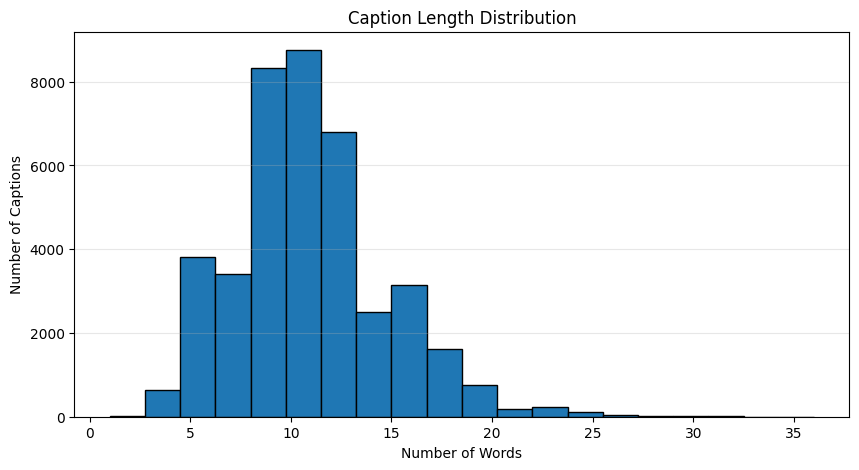

In [15]:

import matplotlib.pyplot as plt

# Calculate caption lengths without special tokens
caption_lengths = processed_captions["clean_caption"].apply(
    lambda caption: len(caption.split()) - 2
)

print("CAPTION LENGTH STATISTICS")
print("Minimum length:", caption_lengths.min())
print("Maximum length:", caption_lengths.max())
print(f"Average length: {caption_lengths.mean():.2f}")
print("Median length:", caption_lengths.median())

# Plot caption length distribution
plt.figure(figsize=(10, 5))

plt.hist(caption_lengths, bins=20, edgecolor="black")

plt.title("Caption Length Distribution")
plt.xlabel("Number of Words")
plt.ylabel("Number of Captions")

plt.grid(axis="y", alpha=0.3)
plt.show()


### 10.1 Caption Length Results

The caption-length analysis shows that the shortest caption contains 1 word, while the longest contains 36 words.

The average caption length is 10.79 words, and the median length is 10 words.

These results indicate that most captions are relatively short. The caption-length distribution will help us decide how to handle sequence padding during model training.

### 11. Text-to-Sequence Conversion

Computer models cannot understand raw words. They can only work with numbers.

Because of this, we must change every word in our descriptions into a number using our vocabulary dictionary.

### Simple Example:
If our dictionary looks like this:
- `"<start>"` -> 2
- `"a"` -> 11
- `"dog"` -> 45
- `"runs"` -> 99
- `"<end>"` -> 3

Then the sentence:
`"<start> a dog runs <end>"`

Will become this list of numbers:
`[2, 11, 45, 99, 3]`

If a word is not in our dictionary, we will simply replace it with the number for `"<unk>"`.

In [16]:

# Function to convert a caption into a numerical sequence
def caption_to_sequence(caption):
    words = caption.split()

    sequence = [
        word2idx.get(word, word2idx["<unk>"])
        for word in words
    ]

    return sequence


# Convert captions in all three datasets
train_df["sequence"] = train_df["clean_caption"].apply(
    caption_to_sequence
)

val_df["sequence"] = val_df["clean_caption"].apply(
    caption_to_sequence
)

test_df["sequence"] = test_df["clean_caption"].apply(
    caption_to_sequence
)


# Display one example
sample_caption = train_df["clean_caption"].iloc[0]
sample_sequence = train_df["sequence"].iloc[0]

print("ORIGINAL CAPTION:")
print(sample_caption)

print("\nNUMERICAL SEQUENCE:")
print(sample_sequence)

print("\nSEQUENCE LENGTH:")
print(len(sample_sequence))


ORIGINAL CAPTION:
<start> a black dog and a spotted dog are fighting <end>

NUMERICAL SEQUENCE:
[2, 11, 230, 639, 53, 11, 2089, 639, 68, 782, 3]

SEQUENCE LENGTH:
11


### 12. Sequence Padding

Our sentences do not all have the same length. Some are short, and some are long.

To make training faster and easier, the computer model expects every sentence to have the exact same length.

To fix this, we do two things:
1. Find the longest sentence in our dataset (which has 38 words).
2. Add extra zeros (the mapping for `<pad>`) to the end of all shorter sentences until they are 38 numbers long.

### Simple Example:
If our maximum length is set to 5, and we have two sentences:
- Sentence A (length 3): `[2, 45, 3]`
- Sentence B (length 5): `[2, 11, 45, 99, 3]`

After adding the `<pad>` token (which is 0), they both become 5 numbers long:
- Sentence A (padded): `[2, 45, 3, 0, 0]`
- Sentence B (padded): `[2, 11, 45, 99, 3]`

In [17]:

# Find the maximum sequence length across all datasets
max_length = max(
    train_df["sequence"].apply(len).max(),
    val_df["sequence"].apply(len).max(),
    test_df["sequence"].apply(len).max()
)

print("Maximum sequence length:", max_length)
print("Padding token index:", word2idx["<pad>"])



Maximum sequence length: 38
Padding token index: 0


In [18]:

from tensorflow.keras.preprocessing.sequence import pad_sequences

# Apply padding to all datasets
train_sequences = pad_sequences(
    train_df["sequence"],
    maxlen=max_length,
    padding="post",
    truncating="post",
    value=word2idx["<pad>"]
)

val_sequences = pad_sequences(
    val_df["sequence"],
    maxlen=max_length,
    padding="post",
    truncating="post",
    value=word2idx["<pad>"]
)

test_sequences = pad_sequences(
    test_df["sequence"],
    maxlen=max_length,
    padding="post",
    truncating="post",
    value=word2idx["<pad>"]
)

print("TRAIN SEQUENCES SHAPE:", train_sequences.shape)
print("VALIDATION SEQUENCES SHAPE:", val_sequences.shape)
print("TEST SEQUENCES SHAPE:", test_sequences.shape)

# Display one padded example
print("\nORIGINAL SEQUENCE:")
print(train_df["sequence"].iloc[0])

print("\nPADDED SEQUENCE:")
print(train_sequences[0])

print("\nPADDED SEQUENCE LENGTH:")
print(len(train_sequences[0]))


TRAIN SEQUENCES SHAPE: (30000, 38)
VALIDATION SEQUENCES SHAPE: (5000, 38)
TEST SEQUENCES SHAPE: (5455, 38)

ORIGINAL SEQUENCE:
[2, 11, 230, 639, 53, 11, 2089, 639, 68, 782, 3]

PADDED SEQUENCE:
[   2   11  230  639   53   11 2089  639   68  782    3    0    0    0
    0    0    0    0    0    0    0    0    0    0    0    0    0    0
    0    0    0    0    0    0    0    0    0    0]

PADDED SEQUENCE LENGTH:
38


### What does this output mean?

Let's break down the results shown above in simple words:

1. **TRAIN SEQUENCES SHAPE: (30000, 38)**
   * This means we now have **30,000** training sentences.
   * Every single one of these sentences is now exactly **38** numbers long.

2. **ORIGINAL SEQUENCE**
   * This was our starting sentence: `[2, 11, 230, 639, 53, 11, 2089, 639, 68, 782, 3]`.
   * It only had **11** numbers because the original sentence was short.

3. **PADDED SEQUENCE**
   * This is the same sentence after padding: `[2, 11, 230, 639, 53, 11, 2089, 639, 68, 782, 3, 0, 0, 0, ...]`.
   * We added **27 zeros** (`0` is the mapping code for `<pad>`) to the end of the list.
   * Now, the short sentence is exactly **38** numbers long, making it match the longest sentence.

# 13. Image Feature Extraction Using CNN

A Convolutional Neural Network (CNN) is used to extract visual features from images.

In this project, ResNet50, pretrained on ImageNet, is selected as the image encoder.

The pretrained classification layer will be removed, and the network will be used as a feature extractor.

The CNN will remain frozen during the initial training process. Each image will be converted into a 2048-dimensional feature vector.

These extracted features will later be provided to the LSTM decoder for caption generation.

### What is PyTorch Device Setup?

* **CPU (Central Processing Unit):** Great for basic tasks, but very slow for processing thousands of image pixels.
* **GPU (Graphics Processing Unit):** Highly recommended for deep learning because it can process thousands of calculations at the same time.
* **Device Selection:** The script checks if a GPU is available. If yes, it selects `cuda`; otherwise, it falls back to `cpu` automatically.

In [19]:

import torch

print("PyTorch version:", torch.__version__)

if torch.cuda.is_available():
    print("GPU Available:", torch.cuda.get_device_name(0))
else:
    print("GPU not available. Using CPU.")

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Selected device:", device)


PyTorch version: 2.14.1+cpu
GPU not available. Using CPU.
Selected device: cpu


In [20]:

import torch
import torch.nn as nn
from torchvision import models

# Load pretrained ResNet50
weights = models.ResNet50_Weights.DEFAULT

resnet = models.resnet50(weights=weights)

# Remove the final classification layer
resnet = nn.Sequential(*list(resnet.children())[:-1])

# Freeze all CNN parameters
for parameter in resnet.parameters():
    parameter.requires_grad = False

# Move model to selected device
resnet = resnet.to(device)

# Set model to evaluation mode
resnet.eval()

print("ResNet50 loaded successfully.")
print("Final classification layer removed.")
print("CNN parameters frozen.")


Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 213MB/s]


ResNet50 loaded successfully.
Final classification layer removed.
CNN parameters frozen.


### Understanding CNN Encoder Steps:

* **ResNet50:** A famous pre-trained neural network that is excellent at identifying objects in images.
* **No Classifier:** We strip away the last classification layer because we do not want to classify the image into 1000 classes. We only want its raw visual features.
* **Frozen Weights:** We set `requires_grad = False` so the pre-trained weights do not change during our training process.

### 14. Image Preprocessing

Before extracting image features, all images must be converted into a consistent format.

The preprocessing steps include:

- Loading images in RGB format.
- Resizing images to 224 × 224 pixels.
- Converting images into PyTorch tensors.
- Applying ImageNet normalization.

The same preprocessing configuration used by the pretrained ResNet50 model is applied to all images.

### 14.1 Initializing Preprocessing Transformations

We load the default visual transforms provided by ResNet50 to ensure our inputs precisely match the expected ImageNet input distribution.

In [21]:

from torchvision import transforms
from PIL import Image

# Get the preprocessing transformation for ResNet50
preprocess = weights.transforms()

print("Image preprocessing pipeline:")
print(preprocess)


Image preprocessing pipeline:
ImageClassification(
    crop_size=[224]
    resize_size=[232]
    mean=[0.485, 0.456, 0.406]
    std=[0.229, 0.224, 0.225]
    interpolation=InterpolationMode.BILINEAR
)


### 14.2 Verifying One Image Transformation

Let's apply our preprocessing pipeline on a single sample image from the dataset to verify that its output dimensions, range, and format conform to expectations.

In [22]:

# Select one image from the dataset
sample_image_path = images_dir / train_df["image_name"].iloc[0]

# Open image and convert to RGB
sample_image = Image.open(sample_image_path).convert("RGB")

# Apply preprocessing
sample_tensor = preprocess(sample_image)

print("Original image size:", sample_image.size)
print("Processed tensor shape:", sample_tensor.shape)
print("Tensor data type:", sample_tensor.dtype)
print("Tensor minimum value:", sample_tensor.min().item())
print("Tensor maximum value:", sample_tensor.max().item())


Original image size: (500, 375)
Processed tensor shape: torch.Size([3, 224, 224])
Tensor data type: torch.float32
Tensor minimum value: -1.741159439086914
Tensor maximum value: 2.640000104904175


### 14.3 Extracting Sample Visual Features

We pass the preprocessed single-image tensor through our ResNet50 model to confirm that the feature extraction works and produces a 2048-dimensional output vector.

In [23]:

# Add batch dimension
sample_batch = sample_tensor.unsqueeze(0).to(device)

# Extract features without calculating gradients
with torch.no_grad():
    sample_features = resnet(sample_batch)

# Remove unnecessary dimensions
sample_features = sample_features.squeeze()

print("Feature shape:", sample_features.shape)
print("Number of extracted features:", sample_features.numel())


Feature shape: torch.Size([2048])
Number of extracted features: 2048


### 15.2 Batch-wise Feature Extraction

Extracting features from all images at once can require a large amount of memory.

Therefore, images will be processed in batches using a PyTorch DataLoader.

Each image will be passed through the frozen ResNet50 encoder, and its 2048-dimensional feature vector will be extracted.

Features will be cached so that the CNN does not need to process the images again during decoder training.

### Why do we load images in Batches?

* **Memory Limit:** 8,091 images are very large. If we try to load all of them into the system memory at once, Colab will crash.
* **DataLoader Solution:** PyTorch DataLoader loads images in small packages (batches of 32). It processes 32 images, saves their features, and releases the memory before picking up the next 32.

### 15.7 Training Set Setup for LSTM

Now that our image features are safely extracted, we can build the dataset classes for training our LSTM decoder.

This setup feeds both the image features and the tokenized captions into our model simultaneously.

### 15.3 Creating the Image Loader

We set up a custom dataset class that opens each image file, converts it to RGB, applies our preprocessor, and packages them into small groups (batches) for efficient model computation.

In [24]:

from torch.utils.data import Dataset, DataLoader
from PIL import Image
from pathlib import Path

class FlickrImageDataset(Dataset):

    def __init__(self, image_names, image_directory, transform):
        self.image_names = list(image_names)
        self.image_directory = Path(image_directory)
        self.transform = transform

    def __len__(self):
        return len(self.image_names)

    def __getitem__(self, index):
        image_name = self.image_names[index]

        image_path = self.image_directory / image_name

        image = Image.open(image_path).convert("RGB")

        image_tensor = self.transform(image)

        return image_tensor, image_name


# Get unique image names from the complete dataset
all_image_names = captions_df["image_name"].unique()

# Create image dataset
image_dataset = FlickrImageDataset(
    image_names=all_image_names,
    image_directory=images_dir,
    transform=preprocess
)

# Create DataLoader
BATCH_SIZE = 32

image_loader = DataLoader(
    image_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2
)

print("Total unique images:", len(image_dataset))
print("Batch size:", BATCH_SIZE)
print("Total batches:", len(image_loader))


Total unique images: 8091
Batch size: 32
Total batches: 253


### 15.4 Extracting All Image Features

We pass all images through our ResNet50 model batch by batch and save the computed visual features into a dictionary indexed by the image's filename.

In [25]:

import torch
from tqdm.auto import tqdm

# Dictionary to store image features
image_features = {}

# Keep CNN in evaluation mode
resnet.eval()

# Extract features batch by batch
with torch.no_grad():

    for image_batch, image_names in tqdm(
        image_loader,
        desc="Extracting Image Features"
    ):

        # Move images to GPU or CPU
        image_batch = image_batch.to(device)

        # Extract CNN features
        batch_features = resnet(image_batch)

        # Convert shape from [batch, 2048, 1, 1]
        # to [batch, 2048]
        batch_features = batch_features.squeeze(-1).squeeze(-1)

        # Move features to CPU
        batch_features = batch_features.cpu()

        # Store each feature with its image filename
        for image_name, feature in zip(image_names, batch_features):

            image_features[image_name] = feature

print("\nFEATURE EXTRACTION COMPLETED")
print("Total extracted images:", len(image_features))
print("Feature dimension:", image_features[all_image_names[0]].shape)


Extracting Image Features:   0%|          | 0/253 [00:00<?, ?it/s]


FEATURE EXTRACTION COMPLETED
Total extracted images: 8091
Feature dimension: torch.Size([2048])


### 15.5 Saving Features to Disk

To avoid repeating this time-consuming extraction process every time we train the model, we save the extracted feature dictionary into a file on disk.

In [26]:

import os

# Create directory for extracted features
features_dir = Path("/content/features")
features_dir.mkdir(parents=True, exist_ok=True)

# Save image features
feature_file = features_dir / "resnet50_features.pt"

torch.save(image_features, feature_file)

print("Features saved successfully.")
print("Saved file:", feature_file)
print("File size (MB):", round(os.path.getsize(feature_file) / (1024 ** 2), 2))


Features saved successfully.
Saved file: /content/features/resnet50_features.pt
File size (MB): 64.06


### 15.6 Verifying Saved Features

We reload our saved feature file from disk to ensure that all images have their corresponding visual features properly stored and loaded.

In [27]:

# Load saved features
loaded_features = torch.load(
    feature_file,
    map_location="cpu",
    weights_only=True
)

# Verify feature cache
print("Total images in cache:", len(loaded_features))

# Check one image
sample_name = all_image_names[0]

print("\nSample image:", sample_name)
print("Feature shape:", loaded_features[sample_name].shape)
print("Feature data type:", loaded_features[sample_name].dtype)

# Check for missing image features
missing_images = [
    name for name in all_image_names
    if name not in loaded_features
]

print("\nMissing image features:", len(missing_images))


Total images in cache: 8091

Sample image: 1000268201_693b08cb0e.jpg
Feature shape: torch.Size([2048])
Feature data type: torch.float32

Missing image features: 0


# 16. Model 1: CNN-LSTM Merge Architecture

The first image captioning model uses a CNN-LSTM merge architecture.

The frozen ResNet50 encoder provides a 2048-dimensional image feature vector. A dense layer projects these visual features into a 256-dimensional representation.

The caption input is passed through an embedding layer and an LSTM network with 512 hidden units.

The projected image features are combined with the LSTM outputs. A final dense layer predicts the probability distribution over the vocabulary at each time step.

The model is trained to predict the next word in a caption using the previous words and image features.

### 16.1 Loading Features for the Model

Before initializing our model, we load the pre-extracted ResNet50 features from disk so we can feed them directly into our training pipeline.

In [28]:

# Load previously extracted CNN features
loaded_features = torch.load(
    "/content/features/resnet50_features.pt",
    map_location="cpu",
    weights_only=True
)

print("Loaded image features:", len(loaded_features))
print("Feature dimension:", loaded_features[all_image_names[0]].shape)


Loaded image features: 8091
Feature dimension: torch.Size([2048])


### 16.2 Creating the Captions Dataset Class

This class helps combine our saved image features, input word sequences, and target target words so PyTorch can load them together during training.

In [29]:

from torch.utils.data import Dataset, DataLoader
import torch

class CaptionDataset(Dataset):

    def __init__(self, dataframe, padded_sequences, image_features):

        self.image_names = dataframe["image_name"].tolist()

        # Model input: all tokens except the last
        self.input_sequences = torch.tensor(
            padded_sequences[:, :-1],
            dtype=torch.long
        )

        # Target: all tokens except the first
        self.target_sequences = torch.tensor(
            padded_sequences[:, 1:],
            dtype=torch.long
        )

        self.image_features = image_features

    def __len__(self):
        return len(self.image_names)

    def __getitem__(self, index):

        image_name = self.image_names[index]

        image_feature = self.image_features[image_name]

        input_sequence = self.input_sequences[index]
        target_sequence = self.target_sequences[index]

        return image_feature, input_sequence, target_sequence


# Create datasets
train_dataset = CaptionDataset(
    train_df, train_sequences, loaded_features
)

val_dataset = CaptionDataset(
    val_df, val_sequences, loaded_features
)

test_dataset = CaptionDataset(
    test_df, test_sequences, loaded_features
)

print("Training examples:", len(train_dataset))
print("Validation examples:", len(val_dataset))
print("Testing examples:", len(test_dataset))


Training examples: 30000
Validation examples: 5000
Testing examples: 5455


### 16.3 Creating Data Loaders

We set up PyTorch DataLoaders for our training, validation, and testing splits. This splits our datasets into smaller batches for training.

In [30]:

BATCH_SIZE = 64

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Testing batches:", len(test_loader))


Training batches: 469
Validation batches: 79
Testing batches: 86


### 16.4 Defining the CNN-LSTM Merge Model

This is where we build the neural network. It has an image branch to process the visual features and a caption branch using an LSTM to learn sentence sequences. Finally, it merges them to predict the next word.

### Understanding CNN-LSTM Merge Model Layers:

* **Image Projection (`nn.Linear`):** Shrinks the 2048 ResNet features down to 256 size to match word vectors.
* **Embedding Layer (`nn.Embedding`):** Converts word index numbers into dense 256-dimensional vectors.
* **LSTM Layer (`nn.LSTM`):** Reads the sentence word-by-word and learns grammar and structure.
* **Dropout (`nn.Dropout`):** Randomly deactivates 30% of connections during training to prevent the model from memorizing.

In [31]:

import torch
import torch.nn as nn

class CNNLSTMMerge(nn.Module):

    def __init__(
        self,
        vocab_size,
        image_feature_size=2048,
        embedding_size=256,
        hidden_size=512,
        image_embedding_size=256,
        dropout=0.3
    ):

        super().__init__()

        # Project image features
        self.image_projection = nn.Linear(
            image_feature_size,
            image_embedding_size
        )

        # Convert word indexes into embeddings
        self.embedding = nn.Embedding(
            num_embeddings=vocab_size,
            embedding_dim=embedding_size,
            padding_idx=0
        )

        # Process caption sequences
        self.lstm = nn.LSTM(
            input_size=embedding_size,
            hidden_size=hidden_size,
            batch_first=True
        )

        # Combine image and LSTM representations
        self.dropout = nn.Dropout(dropout)

        self.output_layer = nn.Linear(
            image_embedding_size + hidden_size,
            vocab_size
        )

    def forward(self, image_features, captions):

        # Image branch
        image_embedding = self.image_projection(image_features)

        # Caption branch
        word_embeddings = self.embedding(captions)

        lstm_outputs, _ = self.lstm(word_embeddings)

        # Repeat image features across caption time steps
        image_embedding = image_embedding.unsqueeze(1)

        image_embedding = image_embedding.expand(
            -1,
            lstm_outputs.size(1),
            -1
        )

        # Merge visual and language features
        merged_features = torch.cat(
            (image_embedding, lstm_outputs),
            dim=2
        )

        merged_features = self.dropout(merged_features)

        # Predict vocabulary scores
        outputs = self.output_layer(merged_features)

        return outputs


# Initialize Model 1
vocab_size = len(word2idx)

model1 = CNNLSTMMerge(
    vocab_size=vocab_size
).to(device)

print(model1)


CNNLSTMMerge(
  (image_projection): Linear(in_features=2048, out_features=256, bias=True)
  (embedding): Embedding(2561, 256, padding_idx=0)
  (lstm): LSTM(256, 512, batch_first=True)
  (dropout): Dropout(p=0.3, inplace=False)
  (output_layer): Linear(in_features=768, out_features=2561, bias=True)
)


### 16.5 Testing a Forward Pass

Let's test our model with a single batch to make sure that the network compiles properly and outputs the correct tensor shapes.

In [32]:

# Get one batch
sample_images, sample_inputs, sample_targets = next(iter(train_loader))

# Move batch to selected device
sample_images = sample_images.to(device)
sample_inputs = sample_inputs.to(device)
sample_targets = sample_targets.to(device)

# Forward pass
model1.eval()

with torch.no_grad():
    sample_outputs = model1(
        sample_images,
        sample_inputs
    )

print("Image batch shape:", sample_images.shape)
print("Caption input shape:", sample_inputs.shape)
print("Target shape:", sample_targets.shape)
print("Model output shape:", sample_outputs.shape)


Image batch shape: torch.Size([64, 2048])
Caption input shape: torch.Size([64, 37])
Target shape: torch.Size([64, 37])
Model output shape: torch.Size([64, 37, 2561])


# 17. Model Training

The CNN-LSTM model is trained using Cross Entropy Loss and the Adam optimizer.

Cross Entropy Loss measures the difference between the predicted next-word probabilities and the actual target words.

The padding token is ignored during loss calculation so that padded positions do not affect training.

Gradient clipping is also applied to improve training stability.

The model is evaluated on the validation dataset after every epoch. The model with the lowest validation loss is saved for later evaluation.

### 17.1 Setting Up Loss and Optimization

In this cell, we define the math rules for our training:
- **Loss Function (`nn.CrossEntropyLoss`)**: This measures how many mistakes the model makes. It ignores the padding index (`0`) so the extra blank spaces do not count as mistakes.
- **Optimizer (`Adam`)**: This is the engine that updates the model's weights to help it learn.
- **Epochs and Patience**: We set the model to train for a maximum of 15 rounds (epochs), but we will stop early if the validation performance stops improving for 3 rounds.

In [33]:

import torch.optim as optim

# Define loss function
criterion = nn.CrossEntropyLoss(
    ignore_index=word2idx["<pad>"],
    reduction="sum"
)

# Define optimizer
optimizer = optim.Adam(
    model1.parameters(),
    lr=0.001
)

# Training configuration
EPOCHS = 15
PATIENCE = 3

print("Loss function:", criterion)
print("Optimizer:", optimizer)
print("Learning rate:", optimizer.param_groups[0]["lr"])
print("Maximum epochs:", EPOCHS)


Loss function: CrossEntropyLoss()
Optimizer: Adam (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: False
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.001
    maximize: False
    weight_decay: 0
)
Learning rate: 0.001
Maximum epochs: 15


### 17.2 Training and Validation Functions

Here we create two helper functions to handle the training process step-by-step:
1. **`train_one_epoch`**: This function feeds training batches to the model, calculates the loss, clips gradients to prevent extreme changes, and updates model weights.
2. **`validate_one_epoch`**: This function tests the model's performance on validation data without updating any weights to see how well it generalizes.

In [34]:

def train_one_epoch(model, dataloader, optimizer, criterion, device):

    model.train()

    total_loss = 0
    total_tokens = 0

    for images, captions, targets in dataloader:

        images = images.to(device)
        captions = captions.to(device)
        targets = targets.to(device)

        # Clear previous gradients
        optimizer.zero_grad()

        # Forward pass
        outputs = model(images, captions)

        # Calculate loss
        loss = criterion(
            outputs.reshape(-1, outputs.size(-1)),
            targets.reshape(-1)
        )

        # Count non-padding target tokens
        valid_tokens = (targets != 0).sum()

        # Normalize loss for this batch
        normalized_loss = loss / valid_tokens

        # Backpropagation
        normalized_loss.backward()

        # Prevent excessively large gradients
        torch.nn.utils.clip_grad_norm_(
            model.parameters(),
            max_norm=5.0
        )

        # Update model weights
        optimizer.step()

        total_loss += loss.item()
        total_tokens += valid_tokens.item()

    average_loss = total_loss / total_tokens

    return average_loss


def validate_one_epoch(model, dataloader, criterion, device):

    model.eval()

    total_loss = 0
    total_tokens = 0

    with torch.no_grad():

        for images, captions, targets in dataloader:

            images = images.to(device)
            captions = captions.to(device)
            targets = targets.to(device)

            # Forward pass
            outputs = model(images, captions)

            # Calculate loss
            loss = criterion(
                outputs.reshape(-1, outputs.size(-1)),
                targets.reshape(-1)
            )

            valid_tokens = (targets != 0).sum()

            total_loss += loss.item()
            total_tokens += valid_tokens.item()

    average_loss = total_loss / total_tokens

    return average_loss


### 17.3 Running the Training Loop

This cell runs the actual training loop. In each epoch, the model learns from the training set, checks its accuracy using the validation set, and saves the best model weights if the validation loss drops. If the loss does not improve for 3 consecutive epochs, training will stop early to save time.

In [35]:

import time
import copy
import matplotlib.pyplot as plt

train_losses = []
val_losses = []

best_val_loss = float("inf")
best_model_state = None
epochs_without_improvement = 0

for epoch in range(EPOCHS):

    start_time = time.time()

    # Training
    train_loss = train_one_epoch(
        model1,
        train_loader,
        optimizer,
        criterion,
        device
    )

    # Validation
    val_loss = validate_one_epoch(
        model1,
        val_loader,
        criterion,
        device
    )

    train_losses.append(train_loss)
    val_losses.append(val_loss)

    epoch_time = time.time() - start_time

    print(f"\nEpoch [{epoch + 1}/{EPOCHS}]")
    print(f"Training Loss: {train_loss:.4f}")
    print(f"Validation Loss: {val_loss:.4f}")
    print(f"Time: {epoch_time:.2f} seconds")

    # Save best model
    if val_loss < best_val_loss:

        best_val_loss = val_loss

        best_model_state = copy.deepcopy(model1.state_dict())

        torch.save(
            best_model_state,
            "/content/model1_best.pth"
        )

        epochs_without_improvement = 0

        print("Best model saved.")

    else:

        epochs_without_improvement += 1

    # Early stopping
    if epochs_without_improvement >= PATIENCE:

        print("\nEarly stopping triggered.")
        break


# Restore best model
if best_model_state is not None:
    model1.load_state_dict(best_model_state)

print("\nTRAINING COMPLETED")
print("Best validation loss:", round(best_val_loss, 4))
print("Completed epochs:", len(train_losses))



Epoch [1/15]
Training Loss: 3.4244
Validation Loss: 2.8584
Time: 455.64 seconds
Best model saved.

Epoch [2/15]
Training Loss: 2.6347
Validation Loss: 2.7065
Time: 430.77 seconds
Best model saved.

Epoch [3/15]
Training Loss: 2.3640
Validation Loss: 2.6865
Time: 432.24 seconds
Best model saved.

Epoch [4/15]
Training Loss: 2.1793
Validation Loss: 2.6910
Time: 416.56 seconds

Epoch [5/15]
Training Loss: 2.0366
Validation Loss: 2.7052
Time: 422.28 seconds

Epoch [6/15]
Training Loss: 1.9149
Validation Loss: 2.7309
Time: 408.00 seconds

Early stopping triggered.

TRAINING COMPLETED
Best validation loss: 2.6865
Completed epochs: 6


### 17.4 Plotting Loss Curves

We plot a graph of both training loss and validation loss over all epochs. This helps us visualize if the model is learning correctly or if it is beginning to overfit (memorize) the training data.

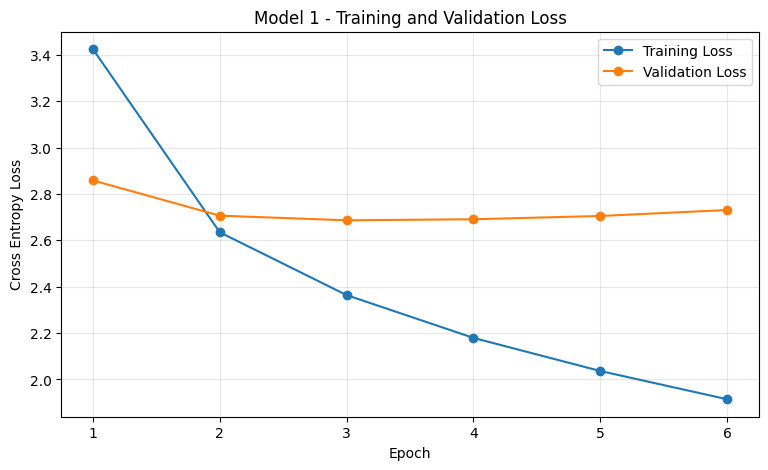

In [36]:

plt.figure(figsize=(9, 5))

plt.plot(
    range(1, len(train_losses) + 1),
    train_losses,
    marker="o",
    label="Training Loss"
)

plt.plot(
    range(1, len(val_losses) + 1),
    val_losses,
    marker="o",
    label="Validation Loss"
)

plt.title("Model 1 - Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Cross Entropy Loss")

plt.xticks(range(1, len(train_losses) + 1))
plt.legend()
plt.grid(alpha=0.3)

plt.show()


### 17.5 Checking the Saved Model File

This simple check verifies that our best-performing model file (`model1_best.pth`) was correctly saved on Colab's disk and prints out its exact size in Megabytes.

In [37]:
import os

model_path = "/content/model1_best.pth"

if os.path.exists(model_path):
    print("Model successfully saved!")
    print(f"File size: {os.path.getsize(model_path) / (1024 * 1024):.2f} MB")
else:
    print("Model file not found.")

Model successfully saved!
File size: 18.03 MB


### 17.6 Connecting Google Drive

We mount Google Drive to Colab so that we can permanently copy and backup our trained model, ensuring we do not lose our progress when the temporary session ends.

In [38]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


### 17.7 Backing Up the Model to Drive

We create a folder in Google Drive and save a copy of our trained model weight file (`model1_best.pth`) there for permanent safe storage.

In [39]:
import os
import shutil

save_dir = "/content/drive/MyDrive/AI101_C3"
os.makedirs(save_dir, exist_ok=True)

shutil.copy2(
    "/content/model1_best.pth",
    f"{save_dir}/model1_best.pth"
)

print("Model permanently saved in Google Drive!")

Model permanently saved in Google Drive!


### 18. Caption Generation — Greedy Search

After training the image captioning model, we use it to generate captions for unseen test images.

Greedy Search selects the word with the highest predicted score at each generation step.

The process starts with the `<start>` token and continues until the model predicts the `<end>` token or reaches the maximum sequence length.

We will compare the generated caption with the five original reference captions for the same image.

### 18.1 Creating the Greedy Search Generator

This function takes an image feature vector and predicts a caption word-by-word. It starts with a `<start>` token, feeds the current sequence into the model, picks the word with the highest predicted score (greedy choice), and repeats this process until it outputs an `<end>` token or hits the maximum allowed length.

In [40]:

def generate_caption_greedy(model, image_feature, max_length, device):
    model.eval()

    # Start with the start token
    sequence = [word2idx["<start>"]]

    image_feature = image_feature.unsqueeze(0).to(device)

    with torch.no_grad():
        for _ in range(max_length - 1):

            caption_input = torch.tensor(
                [sequence],
                dtype=torch.long,
                device=device
            )

            outputs = model(image_feature, caption_input)

            # Get the prediction for the next word
            next_word_scores = outputs[0, -1, :]
            predicted_word = next_word_scores.argmax().item()

            # Stop if the end token is predicted
            if predicted_word == word2idx["<end>"]:
                break

            sequence.append(predicted_word)

    # Convert word indices back into words
    generated_words = [
        idx2word.get(index, "<unk>")
        for index in sequence
    ]

    # Remove special tokens
    generated_words = [
        word for word in generated_words
        if word not in ["<start>", "<end>", "<pad>"]
    ]

    return " ".join(generated_words)


### 18.2 Generating and Comparing Captions

Let's test our trained model! We select a sample image from our unseen test set, generate a caption using our Greedy Search function, and print the generated caption alongside the five original human-written reference captions to evaluate its quality.

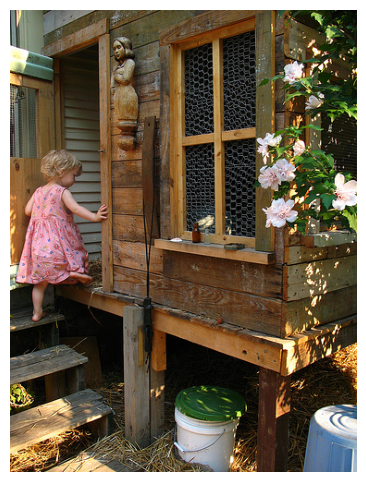

Generated Caption:
a young boy in a red shirt and a brown pants and a brown and white dog is standing in front of a wooden fence

Original Reference Captions:
1. A child in a pink dress is climbing up a set of stairs in an entry way .
2. A girl going into a wooden building .
3. A little girl climbing into a wooden playhouse .
4. A little girl climbing the stairs to her playhouse .
5. A little girl in a pink dress going into a wooden cabin .


In [41]:

import matplotlib.pyplot as plt
from PIL import Image

# Select one image from the test dataset
sample_test_name = test_df["image_name"].iloc[0]

# Load the image
sample_image_path = images_dir / sample_test_name
sample_image = Image.open(sample_image_path).convert("RGB")

# Get the cached ResNet50 features
sample_feature = loaded_features[sample_test_name]

# Generate caption using Greedy Search
generated_caption = generate_caption_greedy(
    model=model1,
    image_feature=sample_feature,
    max_length=max_length,
    device=device
)

# Get all five reference captions
reference_captions = test_df[
    test_df["image_name"] == sample_test_name
]["caption_text"].tolist()

# Display image
plt.figure(figsize=(8, 6))
plt.imshow(sample_image)
plt.axis("off")
plt.show()

print("Generated Caption:")
print(generated_caption)

print("\nOriginal Reference Captions:")
for i, caption in enumerate(reference_captions, start=1):
    print(f"{i}. {caption}")


### 19. Caption Generation — Beam Search

Beam Search is a decoding technique that keeps multiple candidate sequences during caption generation.

Unlike Greedy Search, which selects only the highest-scoring word at each step, Beam Search explores several possible sequences.

We will implement Beam Search with two beam widths:

- Beam width 3
- Beam width 5

The generated captions will be compared with Greedy Search using the same test image.

### 19.1 What is Beam Search?

In simple words, **Beam Search** is an advanced way to generate sentences.

* **The Problem with Greedy Search**: It only looks at the single best word at the current step. If it makes one mistake, the rest of the sentence can become wrong.
* **The Beam Search Solution**: Instead of keeping just 1 word, it keeps a track of the top **k** most likely sentence paths (where **k** is called the **beam width**).

#### Simple Example (Beam Width = 2):
1. At step 1, the model gets the top 2 words: `"a"` and `"the"`.
2. At step 2, it explores options starting with both:
   * `"a dog"`, `"a cat"`
   * `"the dog"`, `"the cat"`
3. It calculates the probability scores for all combinations and keeps only the top 2 overall best paths.

In [42]:

import torch
import torch.nn.functional as F

def generate_caption_beam(model, image_feature, max_length, device, beam_width=3):

    model.eval()

    image_feature = image_feature.unsqueeze(0).to(device)

    start_token = word2idx["<start>"]
    end_token = word2idx["<end>"]

    # Each beam contains: (sequence, cumulative log probability)
    beams = [([start_token], 0.0)]

    with torch.no_grad():

        for _ in range(max_length - 1):

            candidates = []

            for sequence, score in beams:

                # Keep completed sequences unchanged
                if sequence[-1] == end_token:
                    candidates.append((sequence, score))
                    continue

                caption_input = torch.tensor(
                    [sequence],
                    dtype=torch.long,
                    device=device
                )

                outputs = model(image_feature, caption_input)

                # Calculate log probabilities for the next word
                next_word_scores = F.log_softmax(
                    outputs[0, -1, :],
                    dim=-1
                )

                # Prevent special tokens from being generated
                next_word_scores[word2idx["<pad>"]] = float("-inf")
                next_word_scores[start_token] = float("-inf")

                # Select the best possible next words
                top_scores, top_indices = torch.topk(
                    next_word_scores,
                    beam_width
                )

                for i in range(beam_width):

                    next_word = top_indices[i].item()
                    next_score = top_scores[i].item()

                    new_sequence = sequence + [next_word]
                    new_score = score + next_score

                    candidates.append(
                        (new_sequence, new_score)
                    )

            # Keep the highest-scoring candidate sequences
            beams = sorted(
                candidates,
                key=lambda x: x[1],
                reverse=True
            )[:beam_width]

            # Stop if all beams have generated the end token
            if all(sequence[-1] == end_token for sequence, score in beams):
                break

    # Select the sequence with the highest cumulative score
    best_sequence = beams[0][0]

    # Convert indices into words
    generated_words = [
        idx2word.get(index, "<unk>")
        for index in best_sequence
    ]

    # Remove special tokens
    generated_words = [
        word for word in generated_words
        if word not in ["<start>", "<end>", "<pad>"]
    ]

    return " ".join(generated_words)


### 19.2 Testing Beam Search on a Sample Image

Now we will run our newly defined `generate_caption_beam` function on our sample test image.

* We will test it with two different beam widths: **k = 3** and **k = 5**.
* We will print the results side-by-side with our previous **Greedy Search** caption to see which one looks more natural and grammatically correct.

In [43]:

# Generate captions using Beam Search

beam_caption_3 = generate_caption_beam(
    model=model1,
    image_feature=sample_feature,
    max_length=max_length,
    device=device,
    beam_width=3
)

beam_caption_5 = generate_caption_beam(
    model=model1,
    image_feature=sample_feature,
    max_length=max_length,
    device=device,
    beam_width=5
)

# Display all three results
print("Greedy Search:")
print(generated_caption)

print("\nBeam Search (k=3):")
print(beam_caption_3)

print("\nBeam Search (k=5):")
print(beam_caption_5)


Greedy Search:
a young boy in a red shirt and a brown pants and a brown and white dog is standing in front of a wooden fence

Beam Search (k=3):
a young girl in a pink shirt is standing in front of a wooden fence

Beam Search (k=5):
a girl in a pink shirt is standing in front of a wooden fence


### 20. Comparison of Decoding Strategies

We compare three decoding strategies using the same test image:

1. Greedy Search
2. Beam Search with beam width 3
3. Beam Search with beam width 5

This comparison helps us observe how different decoding strategies affect the generated captions.

We will also evaluate these strategies quantitatively using BLEU scores on the complete test set.

### 21. Generating Captions for the Complete Test Set

We now generate captions for all 1,091 test images using Model 1.

For each image, we use three decoding strategies:

1. Greedy Search
2. Beam Search with beam width 3
3. Beam Search with beam width 5

We also store all five original reference captions for each image. These predictions will be used later to calculate corpus BLEU scores and compare the decoding strategies.

### 21. Bulk Test Caption Generation

To perform a fair evaluation, we must generate captions for all 1,091 images in our test dataset.

We will save these predictions to a CSV file. This allows us to compare results without having to rerun the time-consuming generation functions again.

### 21.1 Code Workflow for Bulk Generation

To evaluate our model thoroughly, we must run predictions over the entire test subset of **1,091 images**.

* **Looping**: We loop through each image in the test set.
* **Prediction**: For each image, we generate three different captions:
  1. One using **Greedy Search**.
  2. One using **Beam Search (k=3)**.
  3. One using **Beam Search (k=5)**.
* **Storage**: We save all predictions along with the original human-written references into a single CSV file `/content/model1_test_predictions.csv`.

In [44]:

import pandas as pd
from tqdm.auto import tqdm

# Get unique test image names
test_image_names = test_df["image_name"].unique()

# Store the five reference captions for each image
reference_dict = (
    test_df.groupby("image_name")["caption_text"]
    .apply(list)
    .to_dict()
)

model1_results = []

# Generate captions for every test image
model1.eval()

for image_name in tqdm(test_image_names, desc="Generating Model 1 captions"):

    image_feature = loaded_features[image_name]

    # Greedy Search
    greedy_caption = generate_caption_greedy(
        model=model1,
        image_feature=image_feature,
        max_length=max_length,
        device=device
    )

    # Beam Search k=3
    beam3_caption = generate_caption_beam(
        model=model1,
        image_feature=image_feature,
        max_length=max_length,
        device=device,
        beam_width=3
    )

    # Beam Search k=5
    beam5_caption = generate_caption_beam(
        model=model1,
        image_feature=image_feature,
        max_length=max_length,
        device=device,
        beam_width=5
    )

    model1_results.append({
        "image_name": image_name,
        "greedy_caption": greedy_caption,
        "beam3_caption": beam3_caption,
        "beam5_caption": beam5_caption,
        "references": reference_dict[image_name]
    })

# Convert results into a DataFrame
model1_predictions_df = pd.DataFrame(model1_results)

# Save predictions
model1_predictions_df.to_csv(
    "/content/model1_test_predictions.csv",
    index=False
)

print("Model 1 test predictions generated successfully!")
print("Total test images:", len(model1_predictions_df))
print("Columns:", model1_predictions_df.columns.tolist())

model1_predictions_df.head()


Generating Model 1 captions:   0%|          | 0/1091 [00:00<?, ?it/s]

Model 1 test predictions generated successfully!
Total test images: 1091
Columns: ['image_name', 'greedy_caption', 'beam3_caption', 'beam5_caption', 'references']


,image_name,greedy_caption,beam3_caption,beam5_caption,references
0,1000268201_693b08cb0e.jpg,a young boy in a red shirt and a brown pants a...,a young girl in a pink shirt is standing in fr...,a girl in a pink shirt is standing in front of...,[A child in a pink dress is climbing up a set ...
1,1019604187_d087bf9a5f.jpg,a white dog is running through a field,a dog chases a ball,a dog chases a ball,[A dog prepares to catch a thrown object in a ...
2,1022454428_b6b660a67b.jpg,a man is sitting on a dock with a man in a <unk>,a man in a black shirt and a woman in a helmet,a man and a woman in a <unk> ride,"[A couple and an infant , being held by the ma..."
3,102351840_323e3de834.jpg,a man is standing on a snowy surface near the ...,a man in a red jacket is standing on a snowy s...,a man in a red jacket is standing on a snowy s...,"[A man drilling a hole in the ice ., A man is ..."
4,1028205764_7e8df9a2ea.jpg,a man in a blue shirt and a blue shirt is stan...,a man and a woman in a blue kayak,a man and a woman in a blue kayak,[A man and a baby are in a yellow kayak on wat...


### 22. Verification of Generated Test Captions

We verify that predictions have been generated for all test images.

Each image should contain three generated captions and five original reference captions. The saved predictions will be reused for the evaluation and comparison stages.

In [45]:

# Verify the generated predictions

print("Total images:", len(model1_predictions_df))
print("Expected images:", len(test_images))

print(
    "Images with five references:",
    model1_predictions_df["references"].apply(len).eq(5).sum()
)

print("\nSample predictions:")

sample_result = model1_predictions_df.iloc[0]

print("Image:", sample_result["image_name"])
print("Greedy:", sample_result["greedy_caption"])
print("Beam k=3:", sample_result["beam3_caption"])
print("Beam k=5:", sample_result["beam5_caption"])

print("\nReference captions:")
for i, caption in enumerate(sample_result["references"], start=1):
    print(f"{i}. {caption}")


Total images: 1091
Expected images: 1091
Images with five references: 1091

Sample predictions:
Image: 1000268201_693b08cb0e.jpg
Greedy: a young boy in a red shirt and a brown pants and a brown and white dog is standing in front of a wooden fence
Beam k=3: a young girl in a pink shirt is standing in front of a wooden fence
Beam k=5: a girl in a pink shirt is standing in front of a wooden fence

Reference captions:
1. A child in a pink dress is climbing up a set of stairs in an entry way .
2. A girl going into a wooden building .
3. A little girl climbing into a wooden playhouse .
4. A little girl climbing the stairs to her playhouse .
5. A little girl in a pink dress going into a wooden cabin .


### 23. BLEU Score Evaluation

We use the BLEU metric to evaluate the quality of generated image captions.

Before calculating BLEU, we normalize and tokenize both generated captions and reference captions using the same procedure.

Each generated caption is evaluated against five human-written reference captions for the corresponding image.

We calculate cumulative Corpus BLEU-1, BLEU-2, BLEU-3, and BLEU-4 scores for all three decoding strategies.

### 23.1 Preparing Data for BLEU Scoring

To calculate BLEU scores accurately, we need to convert raw sentences into a format that the evaluation tool expects.

* **Tokenization**: We split sentences into lists of words and convert them to lowercase.
  * *Example*: `"A happy dog."` becomes `['a', 'happy', 'dog']`.
* **Lists of Lists**: For each image, we compare 1 generated caption against 5 human references. We group them into structured lists so that Python can evaluate them instantly.

In [46]:

import re
import nltk
from nltk.translate.bleu_score import corpus_bleu, SmoothingFunction

# Tokenize and normalize captions
def tokenize_caption(caption):
    return re.findall(r"[a-z0-9]+", caption.lower())

# Prepare references and hypotheses
references = []

greedy_hypotheses = []
beam3_hypotheses = []
beam5_hypotheses = []

for _, row in model1_predictions_df.iterrows():

    # Five reference captions for each image
    image_references = [
        tokenize_caption(caption)
        for caption in row["references"]
    ]

    references.append(image_references)

    # Generated captions
    greedy_hypotheses.append(
        tokenize_caption(row["greedy_caption"])
    )

    beam3_hypotheses.append(
        tokenize_caption(row["beam3_caption"])
    )

    beam5_hypotheses.append(
        tokenize_caption(row["beam5_caption"])
    )

print("BLEU evaluation data prepared successfully!")

print("Number of images:", len(references))
print("References per image:", len(references[0]))
print("Sample tokenized reference:", references[0][0])
print("Sample tokenized prediction:", greedy_hypotheses[0])


BLEU evaluation data prepared successfully!
Number of images: 1091
References per image: 5
Sample tokenized reference: ['a', 'child', 'in', 'a', 'pink', 'dress', 'is', 'climbing', 'up', 'a', 'set', 'of', 'stairs', 'in', 'an', 'entry', 'way']
Sample tokenized prediction: ['a', 'young', 'boy', 'in', 'a', 'red', 'shirt', 'and', 'a', 'brown', 'pants', 'and', 'a', 'brown', 'and', 'white', 'dog', 'is', 'standing', 'in', 'front', 'of', 'a', 'wooden', 'fence']


### 23.2 Running the BLEU Scoring Formulas

Now we will calculate the **Corpus BLEU-1, BLEU-2, BLEU-3, and BLEU-4** scores for each of our three strategies.

* **BLEU-1**: Measures single word matches (e.g., matching nouns like `dog`, `car`).
* **BLEU-4**: Measures 4-word sequence matches, which shows how grammatically fluent the sentence is.
* **Smoothing**: We use a smoothing function so that very short or slightly different sentences don't get a zero score.

In [47]:

# Define BLEU configurations
bleu_weights = {
    "BLEU-1": (1.0, 0.0, 0.0, 0.0),
    "BLEU-2": (0.5, 0.5, 0.0, 0.0),
    "BLEU-3": (1/3, 1/3, 1/3, 0.0),
    "BLEU-4": (0.25, 0.25, 0.25, 0.25)
}

# Smoothing function
smoothing = SmoothingFunction().method1

# Store scores
bleu_results = {}

prediction_methods = {
    "Greedy Search": greedy_hypotheses,
    "Beam Search (k=3)": beam3_hypotheses,
    "Beam Search (k=5)": beam5_hypotheses
}

# Calculate BLEU scores for each decoding method
for method_name, hypotheses in prediction_methods.items():

    scores = {}

    for metric_name, weights in bleu_weights.items():

        score = corpus_bleu(
            references,
            hypotheses,
            weights=weights,
            smoothing_function=smoothing
        )

        scores[metric_name] = score * 100

    bleu_results[method_name] = scores

# Display results
bleu_results_df = pd.DataFrame(bleu_results).T

print("Model 1 — Corpus BLEU Scores")
display(bleu_results_df.round(2))


Model 1 — Corpus BLEU Scores


,BLEU-1,BLEU-2,BLEU-3,BLEU-4
Greedy Search,51.06,34.80,22.59,14.76
Beam Search (k=3),58.95,40.94,27.61,18.70
Beam Search (k=5),60.61,42.08,28.08,19.04


In [48]:

# Save Model 1 BLEU results
bleu_results_df.to_csv(
    "/content/model1_bleu_results.csv"
)

print("BLEU results saved successfully!")


BLEU results saved successfully!


### 24. Analysis of Model 1 BLEU Results

The evaluation was performed on 1,091 test images using five reference captions per image.

The results show that Beam Search outperformed Greedy Search across all four BLEU metrics.

Beam Search with a beam width of 5 achieved the highest scores:

- BLEU-1: 60.61
- BLEU-2: 42.08
- BLEU-3: 28.08
- BLEU-4: 19.04

Compared with Greedy Search, Beam Search with a beam width of 5 improved BLEU-4 from 14.76 to 19.04.

Increasing the beam width from 3 to 5 provided a smaller additional improvement. This suggests that maintaining more candidate sequences helped the model find captions with better reference overlap, although the improvement became smaller at the larger beam width.

These scores measure textual similarity with reference captions and do not necessarily guarantee that every generated caption accurately describes the image.

In [49]:

# Save Model 1 evaluation results and predictions

bleu_results_df.to_csv(
    "/content/model1_bleu_results.csv",
    index=True
)

model1_predictions_df.to_csv(
    "/content/model1_test_predictions.csv",
    index=False
)

print("Model 1 BLEU scores and test predictions saved.")


Model 1 BLEU scores and test predictions saved.


### 25. Model 2 — EfficientNet-B0 + LSTM

For the second model, we use EfficientNet-B0 as the image encoder.

EfficientNet-B0 is an ImageNet-pretrained convolutional neural network. Its classification layer is removed to extract 1280-dimensional image features.

The CNN encoder remains frozen, while the LSTM-based caption decoder is trained on the Flickr8k training captions.

The model uses the same vocabulary, data splits, embedding size, and LSTM hidden size as Model 1. This allows us to compare two different pretrained CNN backbones under a similar caption-generation architecture.

In [50]:

import torch
import torch.nn as nn
from torchvision import models

# Load pretrained EfficientNet-B0
efficientnet_weights = models.EfficientNet_B0_Weights.DEFAULT

efficientnet = models.efficientnet_b0(
    weights=efficientnet_weights
)

# Remove the final classification layer
efficientnet.classifier = nn.Identity()

# Freeze all CNN parameters
for parameter in efficientnet.parameters():
    parameter.requires_grad = False

# Move model to device and set evaluation mode
efficientnet = efficientnet.to(device)
efficientnet.eval()

# Get the correct preprocessing transforms
efficientnet_preprocess = efficientnet_weights.transforms()

print("EfficientNet-B0 loaded successfully!")
print("Feature size: 1280")
print("Device:", device)


Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 79.6MB/s]


EfficientNet-B0 loaded successfully!
Feature size: 1280
Device: cpu


In [51]:

from PIL import Image

# Select one sample image
sample_image_path = images_dir / sample_test_name

sample_image = Image.open(
    sample_image_path
).convert("RGB")

# Apply EfficientNet preprocessing
sample_tensor = efficientnet_preprocess(
    sample_image
).unsqueeze(0).to(device)

# Extract features
with torch.no_grad():
    sample_efficientnet_feature = efficientnet(sample_tensor)

print("Input shape:", sample_tensor.shape)
print("Feature shape:", sample_efficientnet_feature.shape)


Input shape: torch.Size([1, 3, 224, 224])
Feature shape: torch.Size([1, 1280])


### 26. EfficientNet-B0 Feature Extraction

We extract image features from all 8,091 Flickr8k images using the frozen EfficientNet-B0 encoder.

The extracted features are cached and reused during model training. This avoids repeatedly processing the same images through the CNN in every training epoch.

In [52]:

from torch.utils.data import Dataset, DataLoader
from pathlib import Path
from tqdm.auto import tqdm

class EfficientNetImageDataset(Dataset):

    def __init__(self, image_names, images_dir, transform):
        self.image_names = list(image_names)
        self.images_dir = Path(images_dir)
        self.transform = transform

    def __len__(self):
        return len(self.image_names)

    def __getitem__(self, index):
        image_name = self.image_names[index]

        image_path = self.images_dir / image_name

        image = Image.open(image_path).convert("RGB")
        image_tensor = self.transform(image)

        return image_name, image_tensor


# Create dataset and DataLoader
efficientnet_dataset = EfficientNetImageDataset(
    image_names=unique_images,
    images_dir=images_dir,
    transform=efficientnet_preprocess
)

efficientnet_loader = DataLoader(
    efficientnet_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=2,
    pin_memory=(device.type == "cuda")
)

# Extract and cache features
efficientnet_features = {}

efficientnet.eval()

with torch.no_grad():

    for image_names, image_batch in tqdm(
        efficientnet_loader,
        desc="Extracting EfficientNet features"
    ):

        image_batch = image_batch.to(device)

        feature_batch = efficientnet(image_batch)

        feature_batch = feature_batch.cpu()

        for image_name, feature in zip(
            image_names,
            feature_batch
        ):
            efficientnet_features[image_name] = feature

# Save extracted features
feature_dir = Path("/content/features")
feature_dir.mkdir(parents=True, exist_ok=True)

efficientnet_feature_path = (
    feature_dir / "efficientnet_b0_features.pt"
)

torch.save(
    efficientnet_features,
    efficientnet_feature_path
)

print("\nFeature extraction completed!")
print("Total images:", len(efficientnet_features))
print(
    "Feature shape:",
    efficientnet_features[sample_test_name].shape
)
print("Saved at:", efficientnet_feature_path)


Extracting EfficientNet features:   0%|          | 0/253 [00:00<?, ?it/s]


Feature extraction completed!
Total images: 8091
Feature shape: torch.Size([1280])
Saved at: /content/features/efficientnet_b0_features.pt


### 27. Model 2 Architecture

We use an image-captioning merge architecture with EfficientNet-B0 as the image encoder and an LSTM as the text decoder.

The extracted 1280-dimensional image features are projected into a 256-dimensional representation.

The caption tokens are converted into 256-dimensional embeddings and processed by an LSTM with 512 hidden units.

The image representation and LSTM outputs are concatenated and passed through a dropout layer and a linear output layer to predict the next caption word.

In [53]:

class EfficientNetLSTMMerge(nn.Module):

    def __init__(
        self,
        vocab_size,
        image_feature_size=1280,
        embedding_size=256,
        hidden_size=512,
        image_embedding_size=256,
        dropout=0.3
    ):

        super().__init__()

        # Project image features
        self.image_projection = nn.Linear(
            image_feature_size,
            image_embedding_size
        )

        # Convert caption word indices into embeddings
        self.embedding = nn.Embedding(
            vocab_size,
            embedding_size,
            padding_idx=0
        )

        # Process caption sequences
        self.lstm = nn.LSTM(
            input_size=embedding_size,
            hidden_size=hidden_size,
            batch_first=True
        )

        self.dropout = nn.Dropout(dropout)

        # Predict the next word
        self.output_layer = nn.Linear(
            image_embedding_size + hidden_size,
            vocab_size
        )

    def forward(self, image_features, captions):

        image_embedding = self.image_projection(
            image_features
        )

        word_embeddings = self.embedding(captions)

        lstm_outputs, _ = self.lstm(word_embeddings)

        # Repeat image representation across caption positions
        image_embedding = image_embedding.unsqueeze(1).expand(
            -1,
            lstm_outputs.size(1),
            -1
        )

        # Combine image and text information
        merged_features = torch.cat(
            (image_embedding, lstm_outputs),
            dim=2
        )

        merged_features = self.dropout(merged_features)

        outputs = self.output_layer(merged_features)

        return outputs


print("Model 2 architecture defined successfully!")


Model 2 architecture defined successfully!


In [54]:

model2 = EfficientNetLSTMMerge(
    vocab_size=len(final_vocab),
    image_feature_size=1280,
    embedding_size=256,
    hidden_size=512,
    image_embedding_size=256,
    dropout=0.3
).to(device)

total_parameters = sum(
    parameter.numel()
    for parameter in model2.parameters()
)

trainable_parameters = sum(
    parameter.numel()
    for parameter in model2.parameters()
    if parameter.requires_grad
)

print(model2)

print("\nTotal parameters:", f"{total_parameters:,}")
print("Trainable parameters:", f"{trainable_parameters:,}")
print("Device:", device)


EfficientNetLSTMMerge(
  (image_projection): Linear(in_features=1280, out_features=256, bias=True)
  (embedding): Embedding(2561, 256, padding_idx=0)
  (lstm): LSTM(256, 512, batch_first=True)
  (dropout): Dropout(p=0.3, inplace=False)
  (output_layer): Linear(in_features=768, out_features=2561, bias=True)
)

Total parameters: 4,529,921
Trainable parameters: 4,529,921
Device: cpu


In [55]:

# Create one sample image feature
sample_feature = efficientnet_features[sample_test_name]

sample_feature_batch = sample_feature.unsqueeze(0).to(device)

# Create one sample caption input
sample_caption = torch.tensor(
    [train_sequences[0][:-1]],
    dtype=torch.long,
    device=device
)

# Test forward pass
model2.eval()

with torch.no_grad():
    sample_output = model2(
        sample_feature_batch,
        sample_caption
    )

print("Image feature shape:", sample_feature_batch.shape)
print("Caption input shape:", sample_caption.shape)
print("Model output shape:", sample_output.shape)


Image feature shape: torch.Size([1, 1280])
Caption input shape: torch.Size([1, 37])
Model output shape: torch.Size([1, 37, 2561])


/tmp/ipykernel_1098/3057158121.py:7: UserWarning: Creating a tensor from a list of numpy.ndarrays is extremely slow. Please consider converting the list to a single numpy.ndarray with numpy.array() before converting to a tensor. (Triggered internally at /__w/pytorch/pytorch/torch/csrc/utils/tensor_new.cpp:252.)
  sample_caption = torch.tensor(


### 28. Model 2 Dataset Preparation

We prepare the training, validation, and test datasets using the cached EfficientNet-B0 image features.

Each training example contains:

- A 1280-dimensional image feature vector.
- An input caption sequence.
- A target caption sequence shifted by one token.

The input and target sequences allow the model to learn next-word prediction.

In [56]:

from torch.utils.data import Dataset, DataLoader

class CaptionDataset(Dataset):

    def __init__(self, dataframe, padded_sequences, image_features):

        self.image_names = dataframe["image_name"].tolist()

        self.input_sequences = torch.tensor(
            padded_sequences[:, :-1],
            dtype=torch.long
        )

        self.target_sequences = torch.tensor(
            padded_sequences[:, 1:],
            dtype=torch.long
        )

        self.image_features = image_features

    def __len__(self):
        return len(self.image_names)

    def __getitem__(self, index):

        image_name = self.image_names[index]

        image_feature = self.image_features[image_name]

        input_sequence = self.input_sequences[index]

        target_sequence = self.target_sequences[index]

        return image_feature, input_sequence, target_sequence


print("Model 2 Dataset class defined successfully!")


Model 2 Dataset class defined successfully!


In [57]:

# Create Model 2 datasets

train_dataset2 = CaptionDataset(
    train_df,
    train_sequences,
    efficientnet_features
)

val_dataset2 = CaptionDataset(
    val_df,
    val_sequences,
    efficientnet_features
)

test_dataset2 = CaptionDataset(
    test_df,
    test_sequences,
    efficientnet_features
)

print("Model 2 datasets created successfully!")

print("Training examples:", len(train_dataset2))
print("Validation examples:", len(val_dataset2))
print("Test examples:", len(test_dataset2))


Model 2 datasets created successfully!
Training examples: 30000
Validation examples: 5000
Test examples: 5455


### 29. Creating DataLoaders

We use PyTorch DataLoaders to load the dataset in batches.

The batch size is set to 64.

The training DataLoader shuffles the data at the beginning of each epoch, while the validation and test DataLoaders preserve the original order.

In [58]:

BATCH_SIZE = 64

train_loader2 = DataLoader(
    train_dataset2,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=(device.type == "cuda")
)

val_loader2 = DataLoader(
    val_dataset2,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=(device.type == "cuda")
)

test_loader2 = DataLoader(
    test_dataset2,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=(device.type == "cuda")
)

print("Model 2 DataLoaders created successfully!")

print("Training batches:", len(train_loader2))
print("Validation batches:", len(val_loader2))
print("Test batches:", len(test_loader2))


Model 2 DataLoaders created successfully!
Training batches: 469
Validation batches: 79
Test batches: 86


In [59]:

image_batch, caption_input_batch, target_batch = next(
    iter(train_loader2)
)

print("Image batch shape:", image_batch.shape)
print("Caption input shape:", caption_input_batch.shape)
print("Target batch shape:", target_batch.shape)

# Test one forward pass
model2.eval()

with torch.no_grad():

    image_batch = image_batch.to(device)
    caption_input_batch = caption_input_batch.to(device)

    output_batch = model2(
        image_batch,
        caption_input_batch
    )

print("Model output shape:", output_batch.shape)


Image batch shape: torch.Size([64, 1280])
Caption input shape: torch.Size([64, 37])
Target batch shape: torch.Size([64, 37])
Model output shape: torch.Size([64, 37, 2561])


### 30. Model 2 Training Configuration

We train the EfficientNet-B0 + LSTM model using the Flickr8k training dataset.

The model is optimized using Adam with a learning rate of 0.001 and CrossEntropyLoss. Padding tokens are excluded from the loss calculation.

Gradient clipping is applied with a maximum norm of 5.0 to improve training stability.

We train for a maximum of 15 epochs and use early stopping with a patience of 3 epochs. The model checkpoint with the lowest validation loss is saved for later evaluation.

In [60]:

import torch.optim as optim
import time
import os
import copy
import pandas as pd
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

# Loss function
criterion2 = nn.CrossEntropyLoss(
    ignore_index=word2idx["<pad>"],
    reduction="sum"
)

# Separate optimizer for Model 2
optimizer2 = optim.Adam(
    model2.parameters(),
    lr=0.001
)

# Training configuration
EPOCHS2 = 15
PATIENCE2 = 3
GRADIENT_CLIP2 = 5.0

print("Model 2 training configuration ready!")


Model 2 training configuration ready!


In [61]:

def train_one_epoch2(model, loader, criterion, optimizer, device):

    model.train()

    total_loss = 0
    total_tokens = 0

    for image_features, captions, targets in tqdm(
        loader,
        desc="Training",
        leave=False
    ):

        image_features = image_features.to(device)
        captions = captions.to(device)
        targets = targets.to(device)

        optimizer.zero_grad()

        outputs = model(image_features, captions)

        loss = criterion(
            outputs.reshape(-1, outputs.size(-1)),
            targets.reshape(-1)
        )

        loss.backward()

        torch.nn.utils.clip_grad_norm_(
            model.parameters(),
            GRADIENT_CLIP2
        )

        optimizer.step()

        total_loss += loss.item()

        total_tokens += (
            targets != word2idx["<pad>"]
        ).sum().item()

    return total_loss / total_tokens


def evaluate_model2(model, loader, criterion, device):

    model.eval()

    total_loss = 0
    total_tokens = 0

    with torch.no_grad():

        for image_features, captions, targets in tqdm(
            loader,
            desc="Validation",
            leave=False
        ):

            image_features = image_features.to(device)
            captions = captions.to(device)
            targets = targets.to(device)

            outputs = model(image_features, captions)

            loss = criterion(
                outputs.reshape(-1, outputs.size(-1)),
                targets.reshape(-1)
            )

            total_loss += loss.item()

            total_tokens += (
                targets != word2idx["<pad>"]
            ).sum().item()

    return total_loss / total_tokens


print("Training and validation functions defined successfully!")


Training and validation functions defined successfully!


In [62]:

# Checkpoint locations
model2_checkpoint = "/content/model2_best.pth"

drive_checkpoint = (
    "/content/drive/MyDrive/AI101_C3/model2_best.pth"
)

# Training history
train_losses2 = []
val_losses2 = []
epoch_times2 = []

best_val_loss2 = float("inf")
epochs_without_improvement2 = 0

best_model_state2 = None

total_training_start2 = time.time()

for epoch in range(EPOCHS2):

    epoch_start = time.time()

    print(f"\nEpoch [{epoch + 1}/{EPOCHS2}]")

    # Training
    train_loss = train_one_epoch2(
        model2,
        train_loader2,
        criterion2,
        optimizer2,
        device
    )

    # Validation
    val_loss = evaluate_model2(
        model2,
        val_loader2,
        criterion2,
        device
    )

    epoch_time = time.time() - epoch_start

    train_losses2.append(train_loss)
    val_losses2.append(val_loss)
    epoch_times2.append(epoch_time)

    print(f"Training Loss: {train_loss:.4f}")
    print(f"Validation Loss: {val_loss:.4f}")
    print(f"Time: {epoch_time:.2f} seconds")

    # Check for improvement
    if val_loss < best_val_loss2:

        best_val_loss2 = val_loss

        epochs_without_improvement2 = 0

        best_model_state2 = copy.deepcopy(
            model2.state_dict()
        )

        # Save locally
        torch.save(
            best_model_state2,
            model2_checkpoint
        )

        # Save to Google Drive if mounted
        if os.path.isdir("/content/drive/MyDrive/AI101_C3"):

            torch.save(
                best_model_state2,
                drive_checkpoint
            )

            print("Best model saved locally and to Google Drive!")

        else:
            print("Best model saved locally!")

    else:

        epochs_without_improvement2 += 1

        print(
            "No validation improvement:",
            epochs_without_improvement2,
            "/",
            PATIENCE2
        )

    # Early stopping
    if epochs_without_improvement2 >= PATIENCE2:

        print("\nEarly stopping triggered!")

        break


# Restore the best model
model2.load_state_dict(
    torch.load(
        model2_checkpoint,
        map_location=device,
        weights_only=True
    )
)

model2.eval()

total_training_time2 = (
    time.time() - total_training_start2
)

print("\nModel 2 training completed!")
print(f"Best validation loss: {best_val_loss2:.4f}")
print(f"Total training time: {total_training_time2 / 60:.2f} minutes")
print(f"Best model checkpoint: {model2_checkpoint}")



Epoch [1/15]


Training:   0%|          | 0/469 [00:00<?, ?it/s]

Validation:   0%|          | 0/79 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x79717a42aa20>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1706, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1675, in _shutdown_workers
    Exception ignored in: if w.is_alive():
<function _MultiProcessingDataLoaderIter.__del__ at 0x79717a42aa20>  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive

    Traceback (most recent call last):
assert self._parent_pid == os.getpid(), 'can only test a child process'  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1706, in __del__

    AssertionError: can only test a child processself._shutdown_workers()

  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1675, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/

Training Loss: 3.4255
Validation Loss: 2.8790
Time: 407.96 seconds
Best model saved locally and to Google Drive!

Epoch [2/15]


Training:   0%|          | 0/469 [00:00<?, ?it/s]

... (12 outputs left out)

Training Loss: 2.0692
Validation Loss: 2.7293
Time: 436.32 seconds
No validation improvement: 2 / 3

Epoch [6/15]


Training:   0%|          | 0/469 [00:00<?, ?it/s]

Validation:   0%|          | 0/79 [00:00<?, ?it/s]

Training Loss: 1.9546
Validation Loss: 2.7665
Time: 414.24 seconds
No validation improvement: 3 / 3

Early stopping triggered!

Model 2 training completed!
Best validation loss: 2.7203
Total training time: 41.92 minutes
Best model checkpoint: /content/model2_best.pth


### 31. Model 2 Training Results

We record the training loss, validation loss, and training time for each epoch.

The model with the lowest validation loss is restored after training. These results will be used to visualize the learning curves and compare Model 2 with Model 1.

In [63]:

# Create training history table
history2_df = pd.DataFrame({
    "Epoch": range(1, len(train_losses2) + 1),
    "Training Loss": train_losses2,
    "Validation Loss": val_losses2,
    "Time (seconds)": epoch_times2
})

display(history2_df.round(4))

# Save history
history2_df.to_csv(
    "/content/model2_training_history.csv",
    index=False
)

print("Model 2 training history saved!")


,Epoch,Training Loss,Validation Loss,Time (seconds)
0,1,3.4255,2.8790,407.9550
1,2,2.6377,2.7396,412.7741
2,3,2.3790,2.7203,426.8542
3,4,2.2076,2.7217,416.7273
4,5,2.0692,2.7293,436.3206
5,6,1.9546,2.7665,414.2442


Model 2 training history saved!


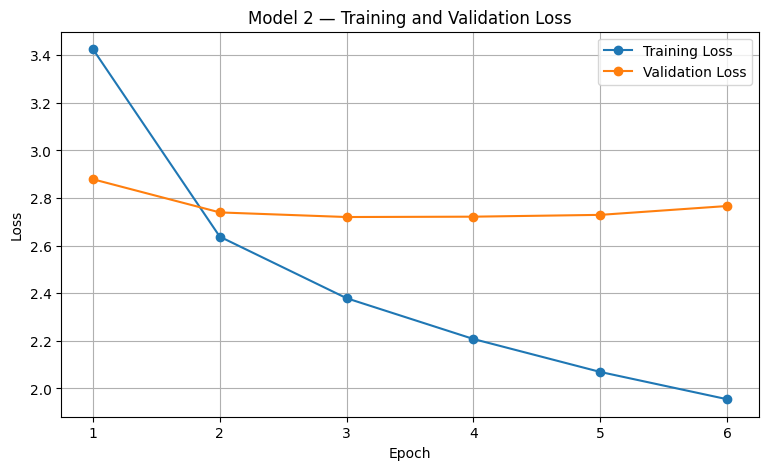

In [64]:

plt.figure(figsize=(9, 5))

plt.plot(
    history2_df["Epoch"],
    history2_df["Training Loss"],
    marker="o",
    label="Training Loss"
)

plt.plot(
    history2_df["Epoch"],
    history2_df["Validation Loss"],
    marker="o",
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Model 2 — Training and Validation Loss")
plt.legend()
plt.grid(True)
plt.show()


### 32. Model 2 — Test Set Caption Generation

We generate captions for all 1,091 test images using the trained EfficientNet-B0 + LSTM model.

Three decoding strategies are used:

1. Greedy Search
2. Beam Search with beam width 3
3. Beam Search with beam width 5

For each image, we also retain its five original reference captions. The same test images and references are used for Model 1 to ensure a fair comparison.

In [65]:

import pandas as pd
from tqdm.auto import tqdm

# Get unique test images
test_image_names = test_df["image_name"].unique()

# Store generated predictions
model2_results = []

model2.eval()

for image_name in tqdm(
    test_image_names,
    desc="Generating Model 2 captions"
):

    # Get EfficientNet image features
    image_feature = efficientnet_features[image_name]

    # Greedy Search
    greedy_caption = generate_caption_greedy(
        model=model2,
        image_feature=image_feature,
        max_length=max_length,
        device=device
    )

    # Beam Search k=3
    beam3_caption = generate_caption_beam(
        model=model2,
        image_feature=image_feature,
        max_length=max_length,
        device=device,
        beam_width=3
    )

    # Beam Search k=5
    beam5_caption = generate_caption_beam(
        model=model2,
        image_feature=image_feature,
        max_length=max_length,
        device=device,
        beam_width=5
    )

    model2_results.append({
        "image_name": image_name,
        "greedy_caption": greedy_caption,
        "beam3_caption": beam3_caption,
        "beam5_caption": beam5_caption,
        "references": reference_dict[image_name]
    })

# Create DataFrame
model2_predictions_df = pd.DataFrame(model2_results)

# Save predictions
model2_predictions_df.to_csv(
    "/content/model2_test_predictions.csv",
    index=False
)

print("Model 2 predictions generated successfully!")
print("Total test images:", len(model2_predictions_df))

display(model2_predictions_df.head())


Generating Model 2 captions:   0%|          | 0/1091 [00:00<?, ?it/s]

Model 2 predictions generated successfully!
Total test images: 1091


,image_name,greedy_caption,beam3_caption,beam5_caption,references
0,1000268201_693b08cb0e.jpg,a little boy in a yellow coat is standing in a...,a little boy in a yellow coat jumps off a wood...,a little boy jumps off a wooden bench,[A child in a pink dress is climbing up a set ...
1,1019604187_d087bf9a5f.jpg,a white dog is running on a lawn,a white dog is playing with a tennis ball in i...,a dog chases a tennis ball,[A dog prepares to catch a thrown object in a ...
2,1022454428_b6b660a67b.jpg,a man in a blue shirt and a woman in a white s...,a man and a woman are standing on a city street,a man and a woman are standing on a city street,"[A couple and an infant , being held by the ma..."
3,102351840_323e3de834.jpg,a man in a blue shirt is holding a fishing pole,a man in a blue shirt is holding a fishing pole,a man and a child are playing in the snow,"[A man drilling a hole in the ice ., A man is ..."
4,1028205764_7e8df9a2ea.jpg,a man in a yellow kayak is sitting on a yellow...,a man in a yellow kayak is sitting in a yellow...,a man in a yellow kayak is sitting on a <unk>,[A man and a baby are in a yellow kayak on wat...


### 33. Verification of Model 2 Predictions

We verify that all test images have three generated captions and five reference captions.

This confirms that the predictions are ready for BLEU evaluation.

In [66]:

print("Total images:", len(model2_predictions_df))
print("Expected images:", len(test_images))

print(
    "Images with five references:",
    model2_predictions_df["references"].apply(len).eq(5).sum()
)

# Display one sample
sample_result2 = model2_predictions_df.iloc[0]

print("\nImage:", sample_result2["image_name"])

print("\nGreedy Search:")
print(sample_result2["greedy_caption"])

print("\nBeam Search (k=3):")
print(sample_result2["beam3_caption"])

print("\nBeam Search (k=5):")
print(sample_result2["beam5_caption"])

print("\nOriginal Reference Captions:")

for i, caption in enumerate(sample_result2["references"], start=1):
    print(f"{i}. {caption}")


Total images: 1091
Expected images: 1091
Images with five references: 1091

Image: 1000268201_693b08cb0e.jpg

Greedy Search:
a little boy in a yellow coat is standing in a doorway

Beam Search (k=3):
a little boy in a yellow coat jumps off a wooden bench

Beam Search (k=5):
a little boy jumps off a wooden bench

Original Reference Captions:
1. A child in a pink dress is climbing up a set of stairs in an entry way .
2. A girl going into a wooden building .
3. A little girl climbing into a wooden playhouse .
4. A little girl climbing the stairs to her playhouse .
5. A little girl in a pink dress going into a wooden cabin .


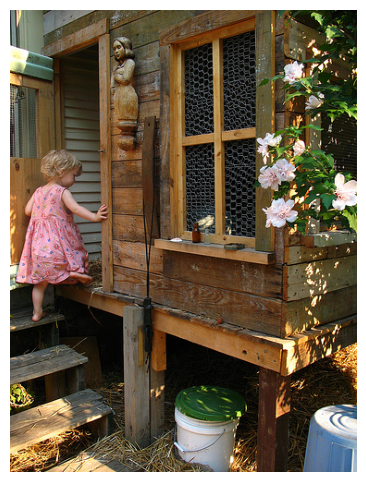

In [67]:

from PIL import Image
import matplotlib.pyplot as plt

sample_name2 = sample_result2["image_name"]

sample_path2 = images_dir / sample_name2

sample_image2 = Image.open(sample_path2).convert("RGB")

plt.figure(figsize=(8, 6))
plt.imshow(sample_image2)
plt.axis("off")
plt.show()


### Preparing Test References

For each test image, we will collect its five original reference captions. These references will be used to evaluate the generated captions using BLEU scores.

The same test images and reference captions will be used for both models to ensure a fair comparison.

In [68]:

# Create a dictionary containing all 5 reference captions for each test image

reference_dict = {}

for image_name in test_images:
    captions = test_df[
        test_df["image_name"] == image_name
    ]["clean_caption"].tolist()

    # Remove <start> and <end> tokens
    captions = [
        caption.replace("<start> ", "").replace(" <end>", "")
        for caption in captions
    ]

    reference_dict[image_name] = captions

# Verify the references
sample_image = test_images[0]

print("Sample image:", sample_image)
print("Number of reference captions:", len(reference_dict[sample_image]))

for i, caption in enumerate(reference_dict[sample_image], 1):
    print(f"{i}. {caption}")


Sample image: 3353278454_2f3a4d0bbc.jpg
Number of reference captions: 5
1. a small dog walks with men in the city
2. some people waiting to cross a busy street in portland oregon
3. the people await to cross the street while walking the dog
4. three guys are waiting to cross the street one has a dog
5. three people wait to cross a city street and one has a dog on a leash


In [69]:

import inspect

print("Greedy function:")
print(inspect.signature(generate_caption_greedy))

print("\nBeam Search function:")
print(inspect.signature(generate_caption_beam))


Greedy function:
(model, image_feature, max_length, device)

Beam Search function:
(model, image_feature, max_length, device, beam_width=3)


In [70]:

from tqdm.auto import tqdm
import pandas as pd
import os

# Set Model 2 to evaluation mode
model2.eval()

model2_results = []

for image_name in tqdm(test_images, desc="Generating Model 2 captions"):

    # Get the cached EfficientNet-B0 image feature
    image_feature = efficientnet_features[image_name]

    # Generate captions using three decoding methods
    greedy_caption = generate_caption_greedy(
        model2, image_feature, max_length, device
    )

    beam3_caption = generate_caption_beam(
        model2, image_feature, max_length, device, beam_width=3
    )

    beam5_caption = generate_caption_beam(
        model2, image_feature, max_length, device, beam_width=5
    )

    # Store predictions and all five reference captions
    model2_results.append({
        "image_name": image_name,
        "references": reference_dict[image_name],
        "greedy": greedy_caption,
        "beam_3": beam3_caption,
        "beam_5": beam5_caption
    })

# Convert results into a DataFrame
model2_predictions_df = pd.DataFrame(model2_results)

# Save predictions
model2_predictions_df.to_csv(
    "/content/model2_test_predictions.csv",
    index=False
)

# Also save to Google Drive if the project folder exists
drive_folder = "/content/drive/MyDrive/AI101_C3"

if os.path.exists(drive_folder):
    model2_predictions_df.to_csv(
        f"{drive_folder}/model2_test_predictions.csv",
        index=False
    )
    print("Predictions also saved to Google Drive.")

print("\nTotal test images:", len(model2_predictions_df))
print("Total generated captions:", len(model2_predictions_df) * 3)

model2_predictions_df.head()


Generating Model 2 captions:   0%|          | 0/1091 [00:00<?, ?it/s]

Predictions also saved to Google Drive.

Total test images: 1091
Total generated captions: 3273


,image_name,references,greedy,beam_3,beam_5
0,3353278454_2f3a4d0bbc.jpg,"[a small dog walks with men in the city, some ...",a man in a yellow shirt is standing on a city ...,a man in a yellow shirt is standing on a city ...,a man in a yellow shirt is standing on a city ...
1,3397220683_4aca010f86.jpg,[a golden retreiver standing outside in the sn...,a dog is jumping through a snow covered ground,a dog jumps through the snow,a dog jumps through the snow
2,500678178_26ce0f4417.jpg,[a child lies in the hay with only a head and ...,a man in a blue shirt is standing on a wooden ...,a man in a blue shirt is standing on a wooden ...,a brown and white dog is running through a pil...
3,937559727_ae2613cee5.jpg,[a blonde fisherman standing in the water prep...,a man in a blue jacket is standing on a <unk>,a man in a blue jacket is <unk> a <unk>,a man in a blue jacket is standing on a <unk>
4,2857609295_16aaa85293.jpg,[a dog catching a frisbee with onlookers in th...,a dog leaps in the air to catch a ball in his ...,a white dog jumps in a field,a dog catching a ball in a field


### BLEU Evaluation and Model Comparison

We evaluate both models using corpus-level BLEU-1, BLEU-2, BLEU-3, and BLEU-4 scores. Each generated caption is compared against all five reference captions for the corresponding test image.

Greedy Search and Beam Search with beam widths of 3 and 5 are evaluated using the same test set.

### Understanding BLEU Scores in Simple Words:

BLEU (Bilingual Evaluation Understudy) measures how similar the machine-generated captions are to the human references.

* **BLEU-1 (Unigrams):** Counts individual word matches. If the model generated `"dog"` and the human wrote `"dog"`, it gets a point.
* **BLEU-4 (4-grams):** Counts matching sequences of 4 words. High BLEU-4 scores mean the sentence flows naturally like human language.

In [72]:
from nltk.translate.bleu_score import corpus_bleu, SmoothingFunction
import pandas as pd

smooth = SmoothingFunction().method1

def calculate_bleu(df, column):
    refs = [
        [caption.split() for caption in row]
        for row in df["references"]
    ]
    hyps = [caption.split() for caption in df[column]]

    return [
        round(corpus_bleu(
            refs, hyps,
            weights=weights,
            smoothing_function=smooth
        ) * 100, 2)
        for weights in [
            (1, 0, 0, 0),
            (0.5, 0.5, 0, 0),
            (1/3, 1/3, 1/3, 0),
            (0.25, 0.25, 0.25, 0.25)
        ]
    ]

# Model 2 scores (using correct column names: 'greedy', 'beam_3', 'beam_5')
model2_scores = []
for method in ["greedy", "beam_3", "beam_5"]:
    model2_scores.append({
        "Model": "EfficientNet-B0",
        "Decoding": method,
        **dict(zip(
            ["txt_BLEU-1", "BLEU-2", "BLEU-3", "BLEU-4"],
            calculate_bleu(model2_predictions_df, method)
        ))
    })

model2_bleu_df = pd.DataFrame(model2_scores)
model2_bleu_df.to_csv("/content/model2_bleu_results.csv", index=False)

# Model 1 scores (using correct column names: 'greedy_caption', 'beam3_caption', 'beam5_caption')
model1_mapping = {
    "greedy": "greedy_caption",
    "beam_3": "beam3_caption",
    "beam_5": "beam5_caption"
}

model1_scores = []
for method_key, method_col in model1_mapping.items():
    model1_scores.append({
        "Model": "ResNet50",
        "Decoding": method_key,
        **dict(zip(
            ["txt_BLEU-1", "BLEU-2", "BLEU-3", "BLEU-4"],
            calculate_bleu(model1_predictions_df, method_col)
        ))
    })

comparison_df = pd.concat(
    [pd.DataFrame(model1_scores), model2_bleu_df],
    ignore_index=True
)

comparison_df.to_csv("/content/final_bleu_comparison.csv", index=False)
comparison_df

,Model,Decoding,txt_BLEU-1,BLEU-2,BLEU-3,BLEU-4
0,ResNet50,greedy,47.26,30.57,19.02,11.77
1,ResNet50,beam_3,55.11,36.34,23.68,15.30
2,ResNet50,beam_5,55.05,36.03,23.30,15.05
3,EfficientNet-B0,greedy,54.66,36.61,23.44,15.10
4,EfficientNet-B0,beam_3,59.90,41.28,27.73,18.73
5,EfficientNet-B0,beam_5,60.81,41.89,28.05,18.79


### Training Analysis and Qualitative Evaluation

We compare the training and validation loss curves of both models. We also measure the number of distinct words generated by each decoding method.

Finally, we inspect generated captions alongside their original images and reference captions to identify good predictions and common errors.

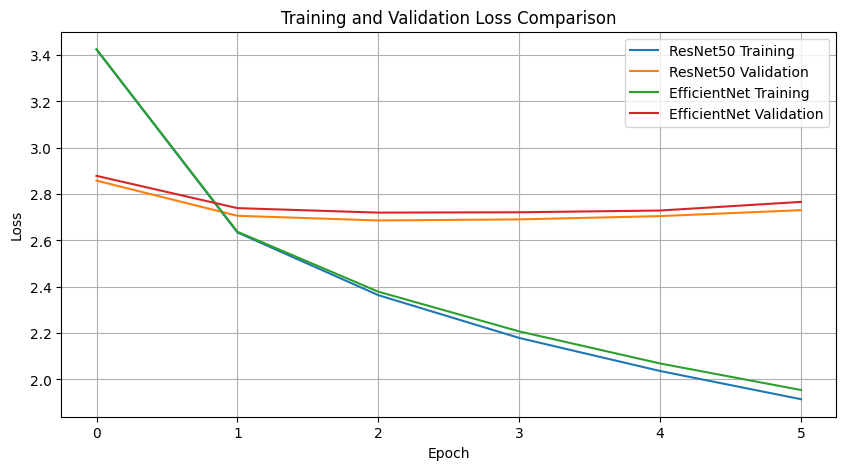

,Model,Decoding,Distinct Words
0,ResNet50,greedy,368
1,ResNet50,beam_3,350
2,ResNet50,beam_5,345
3,EfficientNet-B0,greedy,386
4,EfficientNet-B0,beam_3,394
5,EfficientNet-B0,beam_5,366


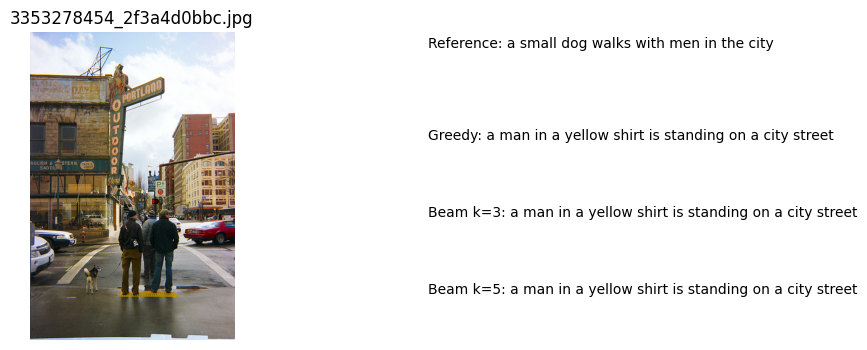

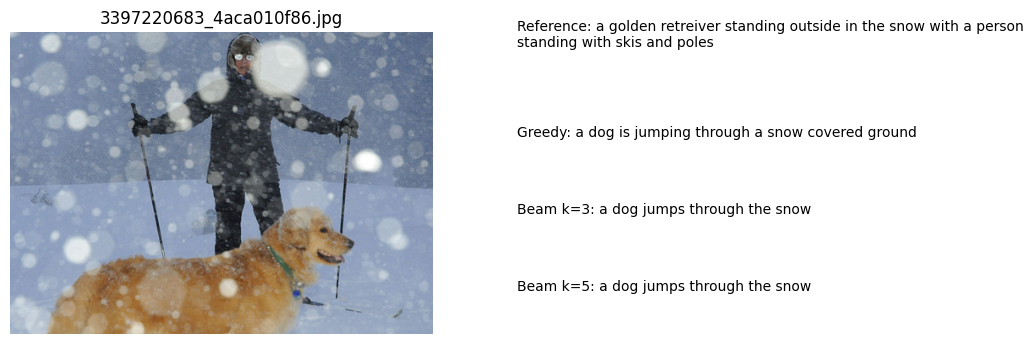

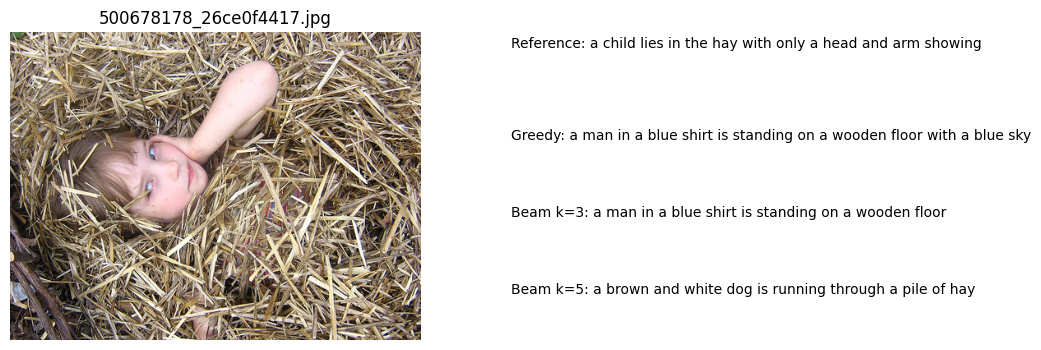

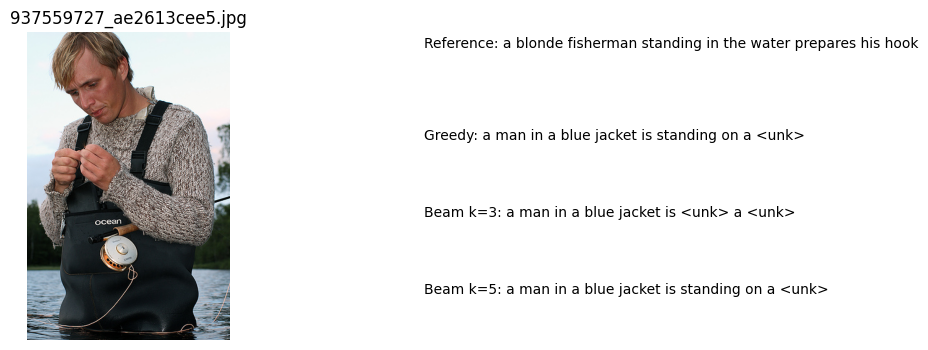

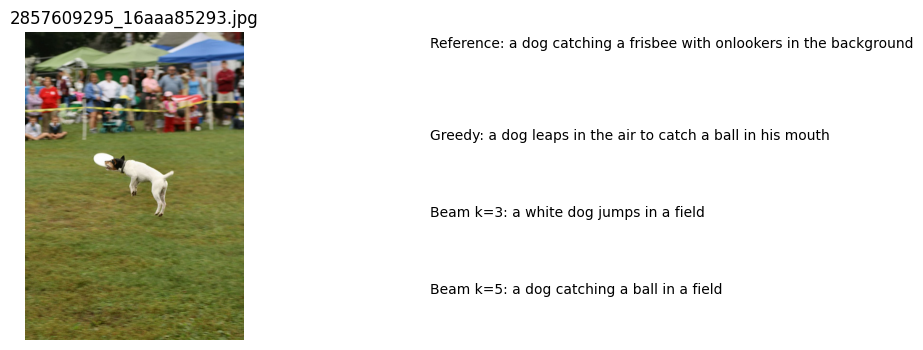

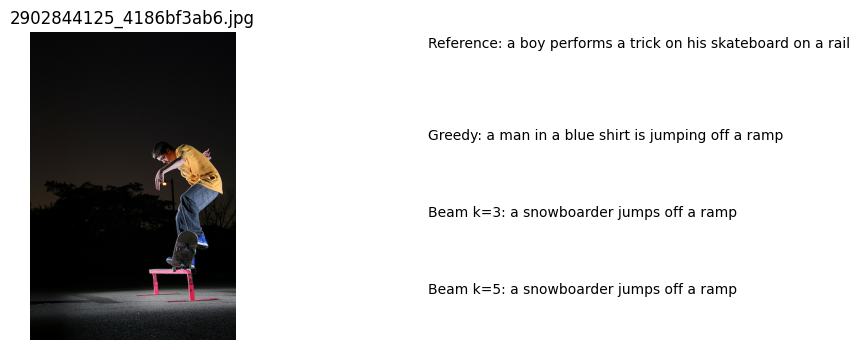

Device: cpu
ResNet50 training time: approximately 42.75 minutes
EfficientNet-B0 training time: approximately 41.92 minutes


In [74]:
import matplotlib.pyplot as plt
from PIL import Image
from collections import Counter
import os

# 1. Compare training and validation loss
plt.figure(figsize=(10, 5))

plt.plot(train_losses, label="ResNet50 Training")
plt.plot(val_losses, label="ResNet50 Validation")
plt.plot(history2_df["Training Loss"], label="EfficientNet Training")
plt.plot(history2_df["Validation Loss"], label="EfficientNet Validation")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training and Validation Loss Comparison")
plt.legend()
plt.grid()
plt.show()

# 2. Count distinct generated words
distinct_results = []

# Dynamic column mapping to resolve name mismatch
model_columns = {
    "ResNet50": {"greedy": "greedy_caption", "beam_3": "beam3_caption", "beam_5": "beam5_caption"},
    "EfficientNet-B0": {"greedy": "greedy", "beam_3": "beam_3", "beam_5": "beam_5"}
}

for model_name, df in [
    ("ResNet50", model1_predictions_df),
    ("EfficientNet-B0", model2_predictions_df)
]:
    mapping = model_columns[model_name]
    for method_key, col_name in mapping.items():
        words = set(
            word
            for caption in df[col_name]
            for word in caption.split()
            if word not in ["<unk>", "<start>", "<end>"]
        )

        distinct_results.append({
            "Model": model_name,
            "Decoding": method_key,
            "Distinct Words": len(words)
        })

distinct_df = pd.DataFrame(distinct_results)
display(distinct_df)

# 3. Display six image-caption examples for manual inspection
for i in range(6):
    row = model2_predictions_df.iloc[i]
    image_path = os.path.join(images_dir, row["image_name"])

    plt.figure(figsize=(12, 4))
    plt.subplot(1, 2, 1)
    plt.imshow(Image.open(image_path))
    plt.axis("off")
    plt.title(row["image_name"])

    plt.subplot(1, 2, 2)
    plt.axis("off")
    plt.text(0, 0.95, "Reference: " + row["references"][0], wrap=True)
    plt.text(0, 0.65, "Greedy: " + row["greedy"], wrap=True)
    plt.text(0, 0.40, "Beam k=3: " + row["beam_3"], wrap=True)
    plt.text(0, 0.15, "Beam k=5: " + row["beam_5"], wrap=True)
    plt.show()

# 4. Hardware and training information
print("Device:", device)
if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

print("ResNet50 training time: approximately 42.75 minutes")
print("EfficientNet-B0 training time: approximately 41.92 minutes")

### Error Analysis

The generated captions may contain several types of errors:

- Object recognition errors: identifying the wrong object.
- Colour errors: describing incorrect colours.
- Action errors: misunderstanding what a person or animal is doing.
- Counting errors: predicting an incorrect number of objects.
- Repetitive captions: generating common and generic descriptions.
- Unknown words: producing `<unk>` tokens for words outside the vocabulary.

### Conclusion

Both image captioning models were evaluated on the same test set of 1,091 images, with five reference captions per image.

EfficientNet-B0 achieved higher BLEU scores than ResNet50 across all three decoding methods in our experiments. Beam Search improved the scores compared with Greedy Search, although higher BLEU scores do not necessarily guarantee better visual understanding.

The results show that the choice of CNN feature extractor and decoding strategy can influence image captioning performance.

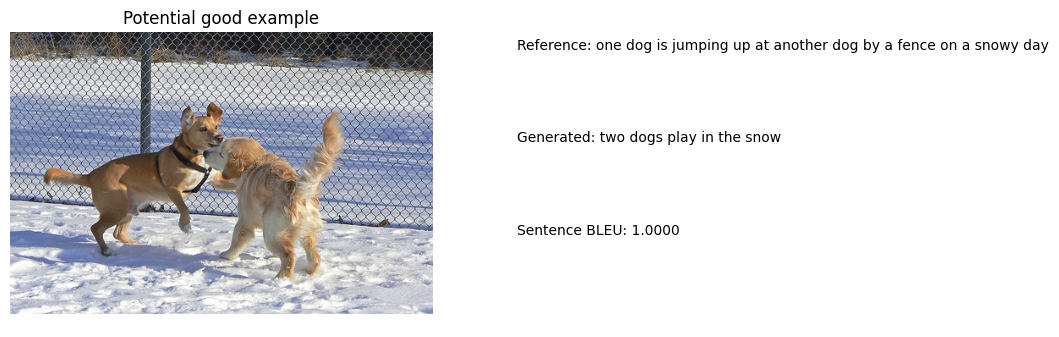

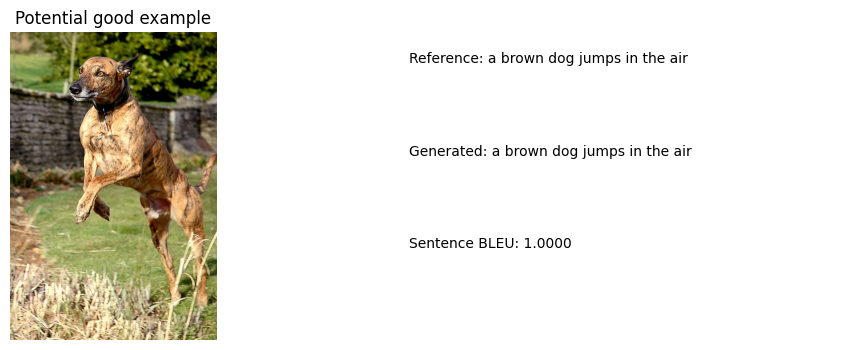

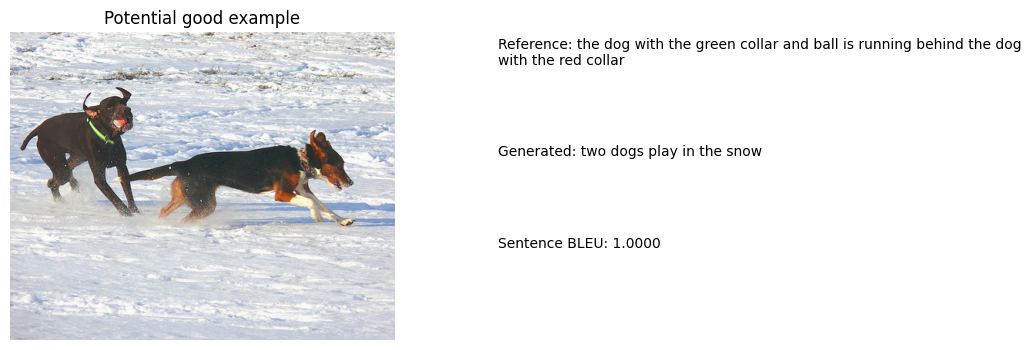

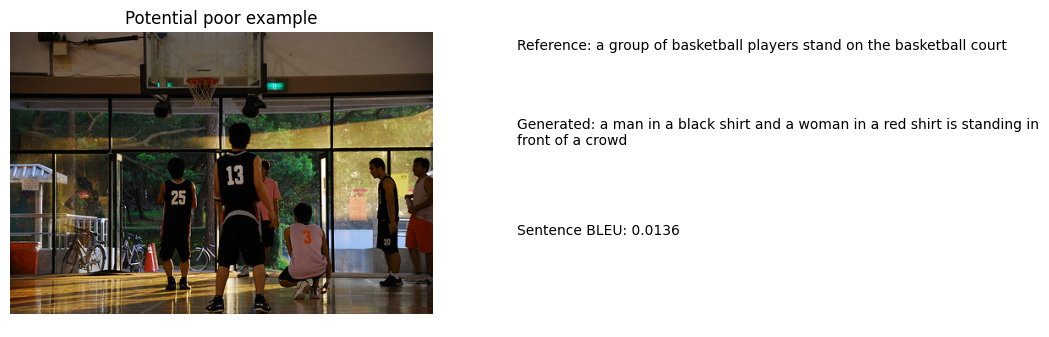

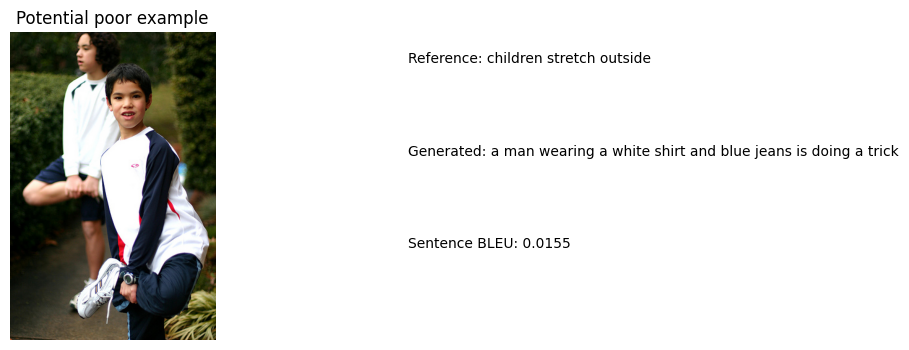

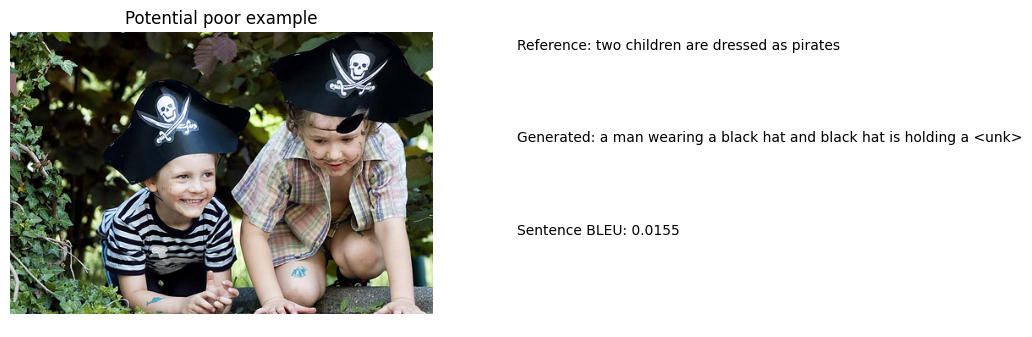

In [75]:

from nltk.translate.bleu_score import sentence_bleu, SmoothingFunction
import matplotlib.pyplot as plt
from PIL import Image
import os

smooth = SmoothingFunction().method1
example_scores = []

for _, row in model2_predictions_df.iterrows():
    refs = [r.split() for r in row["references"]]
    hyp = row["beam_5"].split()

    score = sentence_bleu(
        refs, hyp,
        weights=(0.25, 0.25, 0.25, 0.25),
        smoothing_function=smooth
    )

    example_scores.append(score)

model2_predictions_df["sentence_bleu"] = example_scores

# Select 3 highest and 3 lowest scoring examples
best_examples = model2_predictions_df.nlargest(3, "sentence_bleu")
poor_examples = model2_predictions_df.nsmallest(3, "sentence_bleu")

selected_examples = pd.concat([
    best_examples.assign(example_type="Potential good example"),
    poor_examples.assign(example_type="Potential poor example")
])

for _, row in selected_examples.iterrows():
    image_path = os.path.join(images_dir, row["image_name"])

    plt.figure(figsize=(12, 4))
    plt.subplot(1, 2, 1)
    plt.imshow(Image.open(image_path))
    plt.axis("off")
    plt.title(row["example_type"])

    plt.subplot(1, 2, 2)
    plt.axis("off")
    plt.text(0, 0.9, "Reference: " + row["references"][0], wrap=True)
    plt.text(0, 0.6, "Generated: " + row["beam_5"], wrap=True)
    plt.text(0, 0.3, f"Sentence BLEU: {row['sentence_bleu']:.4f}")
    plt.show()

selected_examples.to_csv(
    "/content/selected_caption_examples.csv", index=False
)


In [76]:

import os
import shutil

backup = "/content/drive/MyDrive/AI101_C3"
os.makedirs(backup, exist_ok=True)

files = [
    "model1_test_predictions.csv",
    "model2_test_predictions.csv",
    "model1_bleu_results.csv",
    "model2_bleu_results.csv",
    "final_bleu_comparison.csv",
    "model2_training_history.csv",
    "selected_caption_examples.csv"
]

for file in files:
    path = "/content/" + file
    if os.path.exists(path):
        shutil.copy2(path, backup)
        print("Saved:", file)

print("\nFinal result files backed up.")


Saved: model1_test_predictions.csv
Saved: model2_test_predictions.csv
Saved: model1_bleu_results.csv
Saved: model2_bleu_results.csv
Saved: final_bleu_comparison.csv
Saved: model2_training_history.csv
Saved: selected_caption_examples.csv

Final result files backed up.
